<a href="https://colab.research.google.com/github/harshalichowdhary-design/NyayaRAG/blob/main/05_NyayaRAG_Generation_and_Evaluation_Qwen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NYAYaRAG — Evidence-Grounded Answer Generation and Safe Abstention

## Pilot Evaluation for RQ3 and RQ4

This notebook implements the generation and abstention components of the
NYAYaRAG framework using a stronger open instruction-tuned language model
running directly on a Google Colab GPU.

The notebook evaluates:

- **RQ3 — Evidence-Grounded Answer Generation:**  
  How accurately does NYAYaRAG generate legally correct, complete, faithful,
  and citation-grounded answers from retrieved Supreme Court judgments?

- **RQ4 — Safe Abstention:**  
  Can NYAYaRAG reliably abstain when the retrieved evidence is insufficient,
  thereby reducing unsupported or hallucinated legal answers?

The retrieval component is fixed as the previously selected **Hybrid
retriever**, and the Top-5 retrieved chunks for each pilot question are used as
the sole evidence supplied to the generator.


In [2]:
# ============================================================
# MOUNT GOOGLE DRIVE AND DEFINE PROJECT ROOT
# ============================================================

# from google.colab import drive
from pathlib import Path

# drive.mount("/content/drive")

PROJECT_ROOT = Path(r"D:\_ResearchNotebooks\NyayaRAG")

assert PROJECT_ROOT.exists(), (
    f"Project root not found: {PROJECT_ROOT}"
)

print("=" * 72)
print("NYAYaRAG PROJECT INITIALISATION")
print("=" * 72)
print(f"Project root : {PROJECT_ROOT}")
print("Status       : READY")

NYAYaRAG PROJECT INITIALISATION
Project root : D:\_ResearchNotebooks\NyayaRAG
Status       : READY


In [ ]:
# ============================================================
# INSTALL REQUIRED LIBRARIES
# ============================================================

!pip -q install -U transformers accelerate bitsandbytes sentencepiece

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 114.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 MB 23.4 MB/s eta 0:00:00


In [3]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import gc
import json
import random

import numpy as np
import pandas as pd
import torch

from pathlib import Path
from tqdm.auto import tqdm

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    pipeline,
)

print("=" * 72)
print("LIBRARIES IMPORTED")
print("=" * 72)

print(f"PyTorch        : {torch.__version__}")
print(f"Transformers   : imported")
print(f"CUDA Available : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU            : {torch.cuda.get_device_name(0)}")

d:\_ResearchNotebooks\NyayaRAG\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LIBRARIES IMPORTED
PyTorch        : 2.8.0+cpu
Transformers   : imported
CUDA Available : False


In [4]:
# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 72)
print("REPRODUCIBILITY")
print("=" * 72)

print(f"Random seed : {SEED}")

REPRODUCIBILITY
Random seed : 42


In [ ]:
# ============================================================
# GPU MEMORY CHECK
# ============================================================

# assert torch.cuda.is_available(), (
#     "Please switch Colab to a GPU runtime."
# )

# gpu_properties = torch.cuda.get_device_properties(0)

# print("=" * 72)
# print("GPU INFORMATION")
# print("=" * 72)

# print(f"GPU                : {gpu_properties.name}")
# print(f"Total Memory (GB)  : {gpu_properties.total_memory/1024**3:.2f}")

AssertionError: Please switch Colab to a GPU runtime.

## 2. Selection of the Colab-Based Generation Model

The generation component is implemented using
`Qwen/Qwen3-4B-Instruct-2507`, an open instruction-tuned language model.

The model is loaded in four-bit quantised form to operate within the memory
constraints of the Tesla T4 GPU while retaining substantially greater
instruction-following capacity than the lightweight local model tested during
the initial Ollama pilot.

The generation model is treated as a fixed component of the NYAYaRAG pipeline.
It is not fine-tuned during this experiment. All pilot questions are processed
using the same model, retrieval depth, prompt, temperature, and decoding
configuration.

In [ ]:
# ============================================================
# DEFINE COLAB GENERATION MODEL CONFIGURATION
# ============================================================

# MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"

# GENERATION_TEMPERATURE = 0.0
# GENERATION_SEED = 42
# MAX_NEW_TOKENS = 600

# USE_4BIT_QUANTISATION = True

# print("=" * 72)
# print("GENERATION MODEL CONFIGURATION")
# print("=" * 72)
# print(f"Model ID              : {MODEL_ID}")
# print(f"Four-bit quantisation : {USE_4BIT_QUANTISATION}")
# print(f"Temperature           : {GENERATION_TEMPERATURE}")
# print(f"Seed                  : {GENERATION_SEED}")
# print(f"Maximum new tokens    : {MAX_NEW_TOKENS}")

GENERATION MODEL CONFIGURATION
Model ID              : Qwen/Qwen3-4B-Instruct-2507
Four-bit quantisation : True
Temperature           : 0.0
Seed                  : 42
Maximum new tokens    : 600


In [5]:
# ============================================================
# IMPORT MODEL-LOADING COMPONENTS
# ============================================================

from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig
)

print("Model-loading components imported successfully.")

Model-loading components imported successfully.


In [ ]:
# ============================================================
# DEFINE FOUR-BIT QUANTISATION
# ============================================================

# quantisation_config = BitsAndBytesConfig(
#     load_in_4bit=True,
#     bnb_4bit_quant_type="nf4",
#     bnb_4bit_compute_dtype=torch.float16,
#     bnb_4bit_use_double_quant=True
# )

# print("=" * 72)
# print("QUANTISATION CONFIGURATION")
# print("=" * 72)
# print("Load in 4-bit        : True")
# print("Quantisation type    : NF4")
# print("Compute dtype        : float16")
# print("Double quantisation  : Enabled")

QUANTISATION CONFIGURATION
Load in 4-bit        : True
Quantisation type    : NF4
Compute dtype        : float16
Double quantisation  : Enabled


In [ ]:
# ============================================================
# LOAD QWEN TOKENIZER AND FOUR-BIT MODEL
# ============================================================

import time

load_started = time.perf_counter()

print("=" * 72)
print("LOADING GENERATION MODEL")
print("=" * 72)
print(f"Model : {MODEL_ID}")
print("This may take several minutes on the first run.\n")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quantisation_config,
    device_map="auto",
    torch_dtype=torch.float16,
    trust_remote_code=True,
    low_cpu_mem_usage=True
)

model.eval()

load_elapsed = time.perf_counter() - load_started

print("\n" + "=" * 72)
print("MODEL LOADING COMPLETE")
print("=" * 72)
print(f"Tokenizer class : {type(tokenizer).__name__}")
print(f"Model class     : {type(model).__name__}")
print(f"Primary device  : {model.device}")
print(f"Load time       : {load_elapsed:.2f} seconds")

LOADING GENERATION MODEL
Model : Qwen/Qwen3-4B-Instruct-2507
This may take several minutes on the first run.



config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]


MODEL LOADING COMPLETE
Tokenizer class : Qwen2Tokenizer
Model class     : Qwen3ForCausalLM
Primary device  : cuda:0
Load time       : 210.42 seconds


In [ ]:
# ============================================================
# VALIDATE MODEL PLACEMENT AND GPU MEMORY
# ============================================================

assert tokenizer is not None, "Tokenizer failed to load."
assert model is not None, "Model failed to load."

allocated_gb = torch.cuda.memory_allocated(0) / 1024**3
reserved_gb = torch.cuda.memory_reserved(0) / 1024**3
total_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3

print("=" * 72)
print("MODEL AND GPU VALIDATION")
print("=" * 72)
print(f"Model ID             : {MODEL_ID}")
print(f"Model training mode  : {model.training}")
print(f"GPU memory allocated : {allocated_gb:.2f} GB")
print(f"GPU memory reserved  : {reserved_gb:.2f} GB")
print(f"Total GPU memory     : {total_gb:.2f} GB")
print("Validation status    : PASSED")

MODEL AND GPU VALIDATION
Model ID             : Qwen/Qwen3-4B-Instruct-2507
Model training mode  : False
GPU memory allocated : 2.49 GB
GPU memory reserved  : 2.54 GB
Total GPU memory     : 14.56 GB
Validation status    : PASSED


## **OPTIONAL : Qwen3-4B-Instruct-2507 running on cloud GPU nVIDIA T4 (endpoint= vllm + ngrok)**

In [6]:
%pip -q install -U openai

Note: you may need to restart the kernel to use updated packages.


In [8]:
import os
from getpass import getpass
from openai import OpenAI

MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
TEMPERATURE = 0.0
SEED = 42
MAX_NEW_TOKENS = 600

NGROK_BASE_URL = "https://dried-moonscape-violet.ngrok-free.dev/v1"

VLLM_API_KEY = "local-dev-key"

client = OpenAI(
    base_url=NGROK_BASE_URL,
    api_key=VLLM_API_KEY,
    timeout=180.0,
    max_retries=2,
)

# Verify that the endpoint is reachable and inspect served model IDs.
available_model_ids = [
    item.id for item in client.models.list().data
]

print("Available models:", available_model_ids)

Available models: ['Qwen/Qwen3-4B-Instruct-2507']


In [9]:
# ============================================================
# QWEN GENERATION CONFIGURATION
# ============================================================

MODEL_NAME = "Qwen/Qwen3-4B-Instruct-2507"
TEMPERATURE = 0.0
SEED = 42
MAX_OUTPUT_TOKENS = 600

print("Model:", MODEL_NAME)
print("Temperature:", TEMPERATURE)
print("Seed:", SEED)
print("Max output tokens:", MAX_OUTPUT_TOKENS)
print("Backend: vLLM via Ngrok")

Model: Qwen/Qwen3-4B-Instruct-2507
Temperature: 0.0
Seed: 42
Max output tokens: 600
Backend: vLLM via Ngrok


In [ ]:
# # ============================================================
# # GENERATE ALL PILOT ANSWERS USING QWEN VIA NGROK
# # ============================================================

# import time
# from datetime import datetime, timezone
# from pathlib import Path

# import pandas as pd
# from tqdm.auto import tqdm

# GENERATION_OUTPUT_DIR = (
#     PROJECT_ROOT
#     / "evaluation"
#     / "pilot"
#     / "generation_qwen_ngrok"
# )

# GENERATION_OUTPUT_DIR.mkdir(
#     parents=True,
#     exist_ok=True
# )

# GENERATION_RESULTS_FILE = (
#     GENERATION_OUTPUT_DIR
#     / "qwen3_4b_pilot_generation_results.csv"
# )


# def generate_one_answer(
#     question_id: str,
#     max_retries: int = 3
# ) -> dict:
#     """Generate one evidence-grounded NYAYaRAG answer."""

#     user_prompt = build_final_user_prompt(question_id)
#     last_error = None

#     for attempt in range(1, max_retries + 1):
#         try:
#             started = time.perf_counter()

#             response = client.chat.completions.create(
#                 model=MODEL_NAME,
#                 messages=[
#                     {
#                         "role": "system",
#                         "content": FINAL_SYSTEM_PROMPT
#                     },
#                     {
#                         "role": "user",
#                         "content": user_prompt
#                     }
#                 ],
#                 temperature=TEMPERATURE,
#                 max_tokens=MAX_OUTPUT_TOKENS,
#                 seed=SEED
#             )

#             elapsed = time.perf_counter() - started

#             raw_response = str(
#                 response.choices[0].message.content or ""
#             ).strip()

#             finish_reason = str(
#                 response.choices[0].finish_reason
#             )

#             parsed = parse_generation_response(
#                 raw_response
#             )

#             # Treat malformed or truncated outputs as failures.
#             if not parsed["format_valid"]:
#                 raise ValueError(
#                     "Response did not follow the required "
#                     "LEGAL ANSWER / AUTHORITIES RELIED UPON format. "
#                     f"Finish reason: {finish_reason}"
#                 )

#             usage = response.usage

#             return {
#                 "generation_status": "success",
#                 "question_id": question_id,
#                 "model_name": MODEL_NAME,
#                 "raw_model_response": raw_response,
#                 "model_decision": parsed["model_decision"],
#                 "generated_answer": parsed["generated_answer"],
#                 "authorities_text": parsed["authorities_text"],
#                 "format_valid": parsed["format_valid"],
#                 "finish_reason": finish_reason,
#                 "prompt_tokens": (
#                     usage.prompt_tokens if usage else None
#                 ),
#                 "thinking_tokens": None,
#                 "answer_tokens": (
#                     usage.completion_tokens if usage else None
#                 ),
#                 "elapsed_seconds": round(elapsed, 3),
#                 "attempts": attempt,
#                 "generated_at_utc": datetime.now(
#                     timezone.utc
#                 ).isoformat(),
#                 "error_message": ""
#             }

#         except Exception as error:
#             last_error = error

#             print(
#                 f"Attempt {attempt}/{max_retries} failed "
#                 f"for {question_id}: {error}"
#             )

#             if attempt < max_retries:
#                 time.sleep(5 * attempt)

#     return {
#         "generation_status": "failure",
#         "question_id": question_id,
#         "model_name": MODEL_NAME,
#         "raw_model_response": "",
#         "model_decision": "",
#         "generated_answer": "",
#         "authorities_text": "",
#         "format_valid": False,
#         "finish_reason": "",
#         "prompt_tokens": None,
#         "thinking_tokens": None,
#         "answer_tokens": None,
#         "elapsed_seconds": None,
#         "attempts": max_retries,
#         "generated_at_utc": datetime.now(
#             timezone.utc
#         ).isoformat(),
#         "error_message": str(last_error)
#     }


# # Generate the pilot dataset.
# generation_records = []

# for question_id in tqdm(
#     pilot_questions["question_id"].tolist(),
#     desc="Generating Qwen answers"
# ):
#     generation_records.append(
#         generate_one_answer(question_id)
#     )

#     time.sleep(2)

# generation_results = pd.DataFrame(generation_records)

# # Compatibility with existing evaluation cells that refer
# # to the old variable name.
# gemini_generation_results = generation_results

# generation_results.to_csv(
#     GENERATION_RESULTS_FILE,
#     index=False,
#     encoding="utf-8-sig"
# )

# print("\n" + "=" * 76)
# print("QWEN GENERATION COMPLETE")
# print("=" * 76)
# print("Total questions:", len(generation_results))
# print(
#     "Successful:",
#     generation_results["generation_status"].eq("success").sum()
# )
# print(
#     "Failed:",
#     generation_results["generation_status"].eq("failure").sum()
# )
# print("Saved to:", GENERATION_RESULTS_FILE)

# display(generation_results)

In [ ]:
#----------------------------------------
# Update the remaining test cells
#----------------------------------------

# response = client.chat.completions.create(
#     model=MODEL_NAME,
#     messages=[
#         {"role": "system", "content": FINAL_SYSTEM_PROMPT},
#         {
#             "role": "user",
#             "content": build_final_user_prompt("RAW002")
#         }
#     ],
#     temperature=TEMPERATURE,
#     max_tokens=MAX_OUTPUT_TOKENS,
#     seed=SEED
# )

# print(response.choices[0].message.content)


## 3. Load and Validate the Pilot Benchmark and Hybrid Retrieval Evidence

The pilot benchmark contains ten legal questions contributed by judicial
officers. For each question, the previously selected Hybrid retriever has
returned the Top-5 judgment chunks.

The generation model will receive only:

- the legal question; and
- the corresponding Top-5 retrieved chunks.

The human answerability labels will be retained separately for later evaluation
of safe abstention and will not be disclosed to the generator.

In [6]:
# ============================================================
# LOAD PILOT QUESTIONS AND HYBRID RETRIEVAL RESULTS
# ============================================================

import pandas as pd
from pathlib import Path

PILOT_QUESTIONS_FILE = (
    PROJECT_ROOT
    / "benchmark"
    / "final"
    / "pilot_questions.csv"
)

HYBRID_RETRIEVAL_FILE = (
    PROJECT_ROOT
    / "evaluation"
    / "pilot"
    / "retrieval"
    / "hybrid_pilot_retrieval.csv"
)

assert PILOT_QUESTIONS_FILE.exists(), (
    f"Pilot-question file not found:\n{PILOT_QUESTIONS_FILE}"
)

assert HYBRID_RETRIEVAL_FILE.exists(), (
    f"Hybrid retrieval file not found:\n{HYBRID_RETRIEVAL_FILE}"
)

pilot_questions = pd.read_csv(
    PILOT_QUESTIONS_FILE
)

hybrid_retrieval = pd.read_csv(
    HYBRID_RETRIEVAL_FILE
)

print("=" * 76)
print("PILOT DATA LOADING")
print("=" * 76)
print(f"Pilot questions loaded : {len(pilot_questions)}")
print(f"Hybrid retrieval rows  : {len(hybrid_retrieval)}")
print(f"Question file          : {PILOT_QUESTIONS_FILE.name}")
print(f"Retrieval file         : {HYBRID_RETRIEVAL_FILE.name}")

PILOT DATA LOADING
Pilot questions loaded : 10
Hybrid retrieval rows  : 50
Question file          : pilot_questions.csv
Retrieval file         : hybrid_pilot_retrieval.csv


In [7]:
# ============================================================
# STANDARDISE COLUMN NAMES
# ============================================================

def standardise_columns(dataframe: pd.DataFrame) -> pd.DataFrame:
    """
    Return a copy with lowercase snake-case column names.
    """

    result = dataframe.copy()

    result.columns = (
        result.columns
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"[^a-z0-9]+", "_", regex=True)
        .str.strip("_")
    )

    return result


pilot_questions = standardise_columns(
    pilot_questions
)

hybrid_retrieval = standardise_columns(
    hybrid_retrieval
)

hybrid_retrieval = hybrid_retrieval.rename(
    columns={
        "global_chunk_id": "chunk_id",
        "rrf_score": "retrieval_score",
        "rank": "retrieval_rank"
    }
)

print("Pilot-question columns:")
print(pilot_questions.columns.tolist())

print("\nHybrid-retrieval columns:")
print(hybrid_retrieval.columns.tolist())

Pilot-question columns:
['question_id', 'contributor', 'experience', 'question_no', 'question', 'word_count']

Hybrid-retrieval columns:
['question_id', 'question', 'chunk_id', 'judgment_id', 'case_title', 'local_chunk_id', 'bm25_rank', 'e5_rank', 'retrieval_score', 'chunk_text', 'retrieval_rank']


In [8]:
# ============================================================
# VALIDATE PILOT BENCHMARK AND HYBRID RETRIEVAL
# ============================================================

required_question_columns = {
    "question_id",
    "question"
}

required_retrieval_columns = {
    "question_id",
    "question",
    "chunk_id",
    "judgment_id",
    "case_title",
    "chunk_text",
    "retrieval_rank",
    "retrieval_score"
}

missing_question_columns = (
    required_question_columns
    - set(pilot_questions.columns)
)

missing_retrieval_columns = (
    required_retrieval_columns
    - set(hybrid_retrieval.columns)
)

assert not missing_question_columns, (
    "Missing pilot-question columns: "
    f"{sorted(missing_question_columns)}"
)

assert not missing_retrieval_columns, (
    "Missing Hybrid retrieval columns: "
    f"{sorted(missing_retrieval_columns)}"
)

assert len(pilot_questions) == 10, (
    f"Expected 10 pilot questions, found {len(pilot_questions)}."
)

assert pilot_questions["question_id"].is_unique, (
    "Duplicate question IDs were found."
)

assert len(hybrid_retrieval) == 50, (
    f"Expected 50 retrieval rows, found {len(hybrid_retrieval)}."
)

chunks_per_question = (
    hybrid_retrieval
    .groupby("question_id")
    .size()
)

assert chunks_per_question.eq(5).all(), (
    "Every pilot question must have exactly five retrieved chunks."
)

benchmark_ids = set(
    pilot_questions["question_id"]
)

retrieval_ids = set(
    hybrid_retrieval["question_id"]
)

assert benchmark_ids == retrieval_ids, (
    "Question IDs in the benchmark and retrieval file do not match."
)

empty_questions = (
    pilot_questions["question"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)

empty_chunks = (
    hybrid_retrieval["chunk_text"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)

assert empty_questions == 0
assert empty_chunks == 0

print("=" * 76)
print("PILOT BENCHMARK AND RETRIEVAL VALIDATION")
print("=" * 76)
print(f"Pilot questions          : {len(pilot_questions)}")
print(f"Unique question IDs      : {pilot_questions['question_id'].nunique()}")
print(f"Hybrid retrieval rows    : {len(hybrid_retrieval)}")
print(f"Chunks per question      : {chunks_per_question.min()}–{chunks_per_question.max()}")
print(f"Empty questions          : {empty_questions}")
print(f"Empty retrieved chunks   : {empty_chunks}")
print("Benchmark–retrieval match: Yes")
print("Validation status        : PASSED")

display(
    pilot_questions[
        [
            "question_id",
            "question"
        ]
    ]
)

PILOT BENCHMARK AND RETRIEVAL VALIDATION
Pilot questions          : 10
Unique question IDs      : 10
Hybrid retrieval rows    : 50
Chunks per question      : 5–5
Empty questions          : 0
Empty retrieved chunks   : 0
Benchmark–retrieval match: Yes
Validation status        : PASSED


,question_id,question
0,RAW001,Under what circumstances can delay in lodging ...
1,RAW002,Can a conviction be sustained solely on the te...
2,RAW004,When may a court interfere with an arbitral aw...
3,RAW005,What are the conditions for granting anticipat...
4,RAW006,Under what circumstances can a court permit am...
5,RAW007,What are the essential ingredients required to...
6,RAW010,What are the mandatory preconditions for exerc...
7,RAW012,Can a civil suit for damages on account of mur...
8,RAW015,How can a magistrate certify the correctness o...
9,RAW017,Can an authorised signatory be convicted under...


## 4. Establish Expert Ground-Truth Answerability Labels

Before answer generation, each pilot question is assigned an expert
ground-truth answerability label based on the sufficiency of the Top-5 Hybrid
retrieval evidence.

The labels are:

- **`answerable`** — the retrieved evidence is sufficient to formulate a
  reliable legal answer; and
- **`insufficient_evidence`** — the retrieved evidence does not adequately
  address the central legal issue and the generator should abstain.

These labels were determined independently through legal review of the
retrieved chunks. They are retained solely for subsequent RQ4 evaluation and
will not be supplied to the generation model.

In [9]:
# ============================================================
# RECORD EXPERT GROUND-TRUTH ANSWERABILITY LABELS
# ============================================================

ANSWERABILITY_GROUND_TRUTH = {
    "RAW001": "answerable",
    "RAW002": "answerable",
    "RAW004": "answerable",
    "RAW005": "answerable",
    "RAW006": "answerable",
    "RAW007": "answerable",
    "RAW010": "insufficient_evidence",
    "RAW012": "insufficient_evidence",
    "RAW015": "answerable",
    "RAW017": "answerable",
}

pilot_questions["answerability_label"] = (
    pilot_questions["question_id"]
    .map(ANSWERABILITY_GROUND_TRUTH)
)

print("=" * 76)
print("EXPERT ANSWERABILITY LABELS")
print("=" * 76)

display(
    pilot_questions[
        [
            "question_id",
            "question",
            "answerability_label"
        ]
    ]
)

EXPERT ANSWERABILITY LABELS


,question_id,question,answerability_label
0,RAW001,Under what circumstances can delay in lodging ...,answerable
1,RAW002,Can a conviction be sustained solely on the te...,answerable
2,RAW004,When may a court interfere with an arbitral aw...,answerable
3,RAW005,What are the conditions for granting anticipat...,answerable
4,RAW006,Under what circumstances can a court permit am...,answerable
5,RAW007,What are the essential ingredients required to...,answerable
6,RAW010,What are the mandatory preconditions for exerc...,insufficient_evidence
7,RAW012,Can a civil suit for damages on account of mur...,insufficient_evidence
8,RAW015,How can a magistrate certify the correctness o...,answerable
9,RAW017,Can an authorised signatory be convicted under...,answerable


In [10]:
# ============================================================
# VALIDATE EXPERT ANSWERABILITY LABELS
# ============================================================

allowed_answerability_labels = {
    "answerable",
    "insufficient_evidence"
}

assert pilot_questions["answerability_label"].notna().all(), (
    "One or more pilot questions do not have an answerability label."
)

unexpected_labels = (
    set(pilot_questions["answerability_label"])
    - allowed_answerability_labels
)

assert not unexpected_labels, (
    f"Unexpected answerability labels: {sorted(unexpected_labels)}"
)

answerability_counts = (
    pilot_questions["answerability_label"]
    .value_counts()
)

assert answerability_counts.get("answerable", 0) == 8, (
    "Expected eight answerable pilot questions."
)

assert answerability_counts.get("insufficient_evidence", 0) == 2, (
    "Expected two insufficient-evidence pilot questions."
)

print("=" * 76)
print("ANSWERABILITY GROUND-TRUTH VALIDATION")
print("=" * 76)
print(f"Questions labelled       : {len(pilot_questions)}")
print(
    f"Answerable               : "
    f"{answerability_counts.get('answerable', 0)}"
)
print(
    f"Insufficient evidence    : "
    f"{answerability_counts.get('insufficient_evidence', 0)}"
)
print("Labels disclosed to model: No")
print("Validation status        : PASSED")

ANSWERABILITY GROUND-TRUTH VALIDATION
Questions labelled       : 10
Answerable               : 8
Insufficient evidence    : 2
Labels disclosed to model: No
Validation status        : PASSED


In [16]:
# ============================================================
# INSTALL GOOGLE GEN AI SDK
# ============================================================

!pip -q install -U google-genai

In [11]:
# ============================================================
# INITIALISE GEMINI
# ============================================================

# from google.colab import userdata
# from google import genai

# API_KEY = userdata.get("GEMINI_API_KEY")

# client = genai.Client(api_key=API_KEY)

# print("=" * 72)
# print("GEMINI INITIALISATION")
# print("=" * 72)
# print("Status : SUCCESS")


import os
from pathlib import Path
from dotenv import load_dotenv
from google import genai

# Project root directory
PROJECT_ROOT = Path(r"D:\_ResearchNotebooks\NyayaRAG")

# Load environment variables from the project root
ENV_PATH = PROJECT_ROOT / ".env"
load_dotenv(dotenv_path=ENV_PATH, override=False)

# Retrieve Gemini API key
GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")

if not GEMINI_API_KEY:
    raise ValueError(
        f"GEMINI_API_KEY not found. Check your .env file: {ENV_PATH}"
    )

# Initialize Gemini client
client = genai.Client(api_key=GEMINI_API_KEY)

print("=" * 72)
print("GEMINI INITIALISATION")
print("=" * 72)
print("Status : SUCCESS")


GEMINI INITIALISATION
Status : SUCCESS


In [12]:
# ============================================================
# LIST AVAILABLE GEMINI MODELS
# ============================================================

for model in client.models.list():
    print(model.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/lyria-3-clip-preview
models/lyria-3-pro-preview
models/l

In [13]:
MODEL_NAME = "models/gemini-3.5-flash-lite"

response = client.models.generate_content(
    model=MODEL_NAME,
    contents="Reply with only the word OK."
)

print(response.text)

OK


In [14]:
# ============================================================
# NYAYaRAG GENERATION MODEL
# ============================================================

MODEL_NAME = "models/gemini-3.5-flash-lite"

print("=" * 72)
print("GENERATION MODEL")
print("=" * 72)
print(f"Model : {MODEL_NAME}")
print("Status: READY")

GENERATION MODEL
Model : models/gemini-3.5-flash-lite
Status: READY


## 5. Evidence-Grounded Prompt Engineering

The generation component of NYAYaRAG is designed to operate as an
evidence-grounded legal research assistant rather than a general-purpose
language model.

To minimise hallucinations and improve trustworthiness, the generator is
explicitly instructed to:

- rely exclusively on the retrieved Supreme Court judgment excerpts;
- avoid using external legal knowledge;
- support legal propositions with the retrieved evidence;
- abstain whenever the supplied evidence is insufficient; and
- produce a structured response suitable for automatic evaluation.

The same prompt is used for every pilot question to ensure methodological
consistency and reproducibility.



In [15]:
# ============================================================
# NYAYaRAG SYSTEM PROMPT
# ============================================================

SYSTEM_PROMPT = """
You are NYAYaRAG, an evidence-grounded legal research assistant.

Your task is to answer legal questions ONLY from the supplied Supreme Court
judgment excerpts.

You must follow these rules strictly.

1. Use ONLY the supplied evidence.

2. Do NOT use outside legal knowledge.

3. Do NOT infer facts that are not supported by the evidence.

4. Every legal proposition must be supported by one or more evidence
sources.

5. If the supplied evidence is insufficient to answer the legal question
reliably, you MUST abstain.

6. Never fabricate legal principles, statutes, cases or citations.

Return your response in EXACTLY the following format.

DECISION:
ANSWER
or
INSUFFICIENT_EVIDENCE

ANSWER:
<your legal answer>

CITATIONS:
S1
or
S1, S2
or
NONE

REASON:
Briefly explain why the evidence was sufficient or insufficient.
"""

print("=" * 72)
print("SYSTEM PROMPT INITIALISED")
print("=" * 72)
print(SYSTEM_PROMPT)

SYSTEM PROMPT INITIALISED

You are NYAYaRAG, an evidence-grounded legal research assistant.

Your task is to answer legal questions ONLY from the supplied Supreme Court
judgment excerpts.

You must follow these rules strictly.

1. Use ONLY the supplied evidence.

2. Do NOT use outside legal knowledge.

3. Do NOT infer facts that are not supported by the evidence.

4. Every legal proposition must be supported by one or more evidence
sources.

5. If the supplied evidence is insufficient to answer the legal question
reliably, you MUST abstain.

6. Never fabricate legal principles, statutes, cases or citations.

Return your response in EXACTLY the following format.

DECISION:
ANSWER
or
INSUFFICIENT_EVIDENCE

ANSWER:
<your legal answer>

CITATIONS:
S1
or
S1, S2
or
NONE

REASON:
Briefly explain why the evidence was sufficient or insufficient.



## 6. Construction of the Evidence Package

For every legal question, the Hybrid retriever has already produced the
Top-5 most relevant judgment chunks.

These chunks are combined into a single evidence package and supplied to the
generation model.

Each retrieved chunk is assigned a stable identifier (`S1`–`S5`), enabling the
generation model to explicitly reference the supporting evidence when answering
the legal question.

In [17]:
# ============================================================
# BUILD EVIDENCE PACKAGE
# ============================================================

def build_evidence_package(question_id):
    """
    Build the evidence package supplied to Gemini.
    """

    rows = (
        hybrid_retrieval
        .query("question_id == @question_id")
        .sort_values("retrieval_rank")
    )

    evidence = []

    for i, (_, row) in enumerate(rows.iterrows(), start=1):

        evidence.append(
f"""
==================================================
SOURCE {i}
==================================================

Case Title:
{row.case_title}

Official Citation:
{row.judgment_id}

Retrieval Rank:
{row.retrieval_rank}

Evidence Excerpt:
{row.chunk_text}
"""
        )

    return "\n".join(evidence)

In [18]:
# ============================================================
# BUILD USER PROMPT
# ============================================================

def build_user_prompt(question_id):

    question = (
        pilot_questions
        .loc[
            pilot_questions.question_id == question_id,
            "question"
        ]
        .iloc[0]
    )

    evidence = build_evidence_package(question_id)

    return f"""
LEGAL QUESTION

{question}


RETRIEVED SUPREME COURT JUDGMENTS

{evidence}


INSTRUCTIONS

Answer ONLY from the retrieved judgments.

Do NOT use any legal knowledge outside these judgments.

Where multiple judgments support the same proposition,
synthesise them into a single legal answer.

Write in clear legal prose.

Do NOT copy the evidence verbatim.

Whenever you rely on a judgment,
cite its official case title and citation.

If the evidence is insufficient,
state that the evidence is insufficient.

Do NOT mention SOURCE 1, SOURCE 2, etc.
Those identifiers are only for internal retrieval.
"""

In [19]:
# ============================================================
# INSPECT FIRST PROMPT
# ============================================================

sample_prompt = build_user_prompt("RAW001")

print(sample_prompt[:6000])


LEGAL QUESTION

Under what circumstances can delay in lodging an FIR prove fatal to prosecution?


RETRIEVED SUPREME COURT JUDGMENTS


SOURCE 1

Case Title:
RAMA DEVI versus THE STATE OF BIHAR AND OTHERS

Official Citation:
[2024] 10 S.C.R. 1313

Retrieval Rank:
1

Evidence Excerpt:
20 See Yogesh Singh v. Mahabeer Singh and Others (2017) 11 SCC 195 which refers to several other decisions. See also State of Rajasthan v. Arjun Singh and Others (2011) 9 SCC 115

[2024] 10 S.C.R. 1337 Rama Devi v. The State of Bihar and Others

(PW-1), Mahanth Ashwani Das (PW-25), and Amarendra Kumar Sinha (PW-10). The inquest reports of Brij Bihari Prasad and Lakshmeshwar Sahu (Exhibits 42/1 and 52) were prepared on the same night and, thereafter, the post-mortem was conducted by Dr. Arvind Kumar Singh (PW-7) at 12:30 a.m. and 1:30 a.m. respectively on 14.06.1998. 30. The occurrence having taken place at night on 13.06.1998, normally the FIR should have been sent to the jurisdictional magistrate on 14.06

In [20]:
# ============================================================
# GENERATE FIRST NYAYaRAG ANSWER
# ============================================================

prompt = build_user_prompt("RAW001")

response = client.models.generate_content(
    model=MODEL_NAME,
    contents=[
        SYSTEM_PROMPT,
        prompt
    ]
)

print(response.text)

DECISION:
INSUFFICIENT_EVIDENCE

ANSWER:
The supplied evidence does not contain sufficient legal principles or circumstances detailing when a delay in *lodging* an FIR can prove fatal to the prosecution. While the evidence discusses that mere delay in the *registration* of an FIR is not a ground for quashing it (*Shento Varghese v. Julfikar Husen & Ors.*, [2024] 6 S.C.R. 409; *Anil Bhavarlal Jain & Anr. v. The State of Maharashtra & Ors.*, [2024] 12 S.C.R. 1436) and that delay in *forwarding* an FIR to the magistrate is not fatal unless prejudice is demonstrated (*Rama Devi v. The State of Bihar and Others*, [2024] 10 S.C.R. 1313; *Shento Varghese v. Julfikar Husen & Ors.*, [2024] 6 S.C.R. 409), it does not specify the circumstances under which a delay in lodging the FIR itself becomes fatal.

CITATIONS:
NONE

REASON:
The retrieved excerpts mention the legal effects of delay in registering an FIR and delay in forwarding an FIR to the magistrate, but they do not provide information on t

## 7. Final Prompt and Batch Generation

Following single-question pilot testing, the generation prompt was simplified
to avoid repetitive decision and explanation fields.

For answerable questions, the model must provide:

1. a concise legal answer in paragraph form; and
2. the Supreme Court authorities relied upon.

For questions where the retrieved evidence is insufficient, the model must
return the prescribed abstention statement and must not attempt an answer.

The prompt, model, retrieval depth, and generation procedure are frozen before
batch generation to prevent question-specific prompt optimisation.

In [21]:
# ============================================================
# FREEZE FINAL NYAYaRAG GENERATION PROMPT
# ============================================================

FINAL_SYSTEM_PROMPT = """
You are NYAYaRAG, an evidence-grounded legal research assistant.

Answer the legal question ONLY from the supplied excerpts of Supreme Court
judgments.

MANDATORY RULES

1. Do not use outside legal knowledge, memory, assumptions, or information
   not contained in the supplied evidence.

2. State only legal propositions that are supported by the supplied judgment
   excerpts.

3. Write the answer as one or more concise legal paragraphs. Avoid numbered
   lists unless they are necessary for clarity.

4. Whenever relying on a judgment, cite its case title and official citation
   exactly as supplied.

5. Do not cite internal retrieval labels such as SOURCE 1, S1, or S2 in the
   legal answer.

6. Do not treat counsel's submissions, allegations, or lower-court reasoning
   as a holding of the Supreme Court unless the excerpt clearly adopts it.

7. Do not invent or alter case names, citations, statutory provisions,
   quotations, facts, procedural history, or holdings.

8. If the supplied evidence does not reliably answer the central legal issue,
   do not guess. Return the prescribed abstention response.

Use exactly one of the following two formats.

FORMAT A — SUFFICIENT EVIDENCE

LEGAL ANSWER

<Substantive legal answer in one or more concise paragraphs, containing
case-title and official-citation references where relied upon.>

AUTHORITIES RELIED UPON

<List each relied-upon judgment once, using its case title and official
citation.>


FORMAT B — INSUFFICIENT EVIDENCE

LEGAL ANSWER

The retrieved judgments do not provide sufficient evidence to answer this
question reliably.

AUTHORITIES RELIED UPON

None

Do not add any other heading, decision label, reason, preface, or conclusion.
""".strip()


MODEL_NAME = "models/gemini-3.5-flash-lite"
MAX_OUTPUT_TOKENS = 1200

print("=" * 76)
print("FINAL GENERATION CONFIGURATION")
print("=" * 76)
print(f"Model                : {MODEL_NAME}")
print("Prompt status        : FROZEN")
print("Retrieval depth      : Top-5 Hybrid chunks")
print(f"Maximum output tokens: {MAX_OUTPUT_TOKENS}")
print("Temperature          : Model default")

FINAL GENERATION CONFIGURATION
Model                : models/gemini-3.5-flash-lite
Prompt status        : FROZEN
Retrieval depth      : Top-5 Hybrid chunks
Maximum output tokens: 1200
Temperature          : Model default


In [22]:
# ============================================================
# BUILD FINAL QUESTION-SPECIFIC USER PROMPT
# ============================================================

def build_final_user_prompt(question_id: str) -> str:
    """
    Build the question-specific prompt without exposing the
    expert answerability label.
    """

    question_rows = pilot_questions.loc[
        pilot_questions["question_id"].eq(question_id),
        "question"
    ]

    if len(question_rows) != 1:
        raise ValueError(
            f"Expected one question for {question_id}, "
            f"found {len(question_rows)}."
        )

    question = question_rows.iloc[0]
    evidence = build_evidence_package(question_id)

    return f"""
LEGAL QUESTION

{question}


RETRIEVED SUPREME COURT JUDGMENT EXCERPTS

{evidence}


TASK

Answer the legal question in accordance with the mandatory rules and one of
the two permitted response formats.
""".strip()

In [23]:
# ============================================================
# PARSE GEMINI RESPONSE
# ============================================================

import re


ABSTENTION_TEXT = (
    "The retrieved judgments do not provide sufficient evidence "
    "to answer this question reliably."
)


def parse_generation_response(response_text: str) -> dict:
    """
    Extract the legal answer and authorities from the fixed text format.
    """

    text = str(response_text or "").strip()

    answer_match = re.search(
        r"LEGAL ANSWER\s*(.*?)\s*AUTHORITIES RELIED UPON",
        text,
        flags=re.IGNORECASE | re.DOTALL
    )

    authorities_match = re.search(
        r"AUTHORITIES RELIED UPON\s*(.*)$",
        text,
        flags=re.IGNORECASE | re.DOTALL
    )

    legal_answer = (
        answer_match.group(1).strip()
        if answer_match
        else ""
    )

    authorities_text = (
        authorities_match.group(1).strip()
        if authorities_match
        else ""
    )

    normalised_answer = " ".join(
        legal_answer.lower().split()
    )

    normalised_abstention = " ".join(
        ABSTENTION_TEXT.lower().split()
    )

    model_decision = (
        "INSUFFICIENT_EVIDENCE"
        if normalised_answer == normalised_abstention
        else "ANSWER"
    )

    format_valid = bool(
        answer_match
        and authorities_match
        and legal_answer
        and authorities_text
    )

    return {
        "model_decision": model_decision,
        "generated_answer": legal_answer,
        "authorities_text": authorities_text,
        "format_valid": format_valid
    }

In [24]:
# ============================================================
# GENERATE ANSWERS FOR ALL 10 PILOT QUESTIONS
# ============================================================

import time
from datetime import datetime, timezone

from google.genai import types
from tqdm.auto import tqdm


GENERATION_OUTPUT_DIR = (
    PROJECT_ROOT
    / "evaluation"
    / "pilot"
    / "generation_gemini"
)

GENERATION_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

GENERATION_RESULTS_FILE = (
    GENERATION_OUTPUT_DIR
    / "gemini35_pilot_generation_results.csv"
)


def generate_one_answer(
    question_id: str,
    max_retries: int = 3
) -> dict:
    """
    Generate and parse one evidence-grounded legal answer.
    """

    user_prompt = build_final_user_prompt(question_id)

    last_error = None

    for attempt in range(1, max_retries + 1):

        try:
            started = time.perf_counter()

            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=user_prompt,
                config=types.GenerateContentConfig(
                    system_instruction=FINAL_SYSTEM_PROMPT,
                    max_output_tokens=MAX_OUTPUT_TOKENS,
                    response_mime_type="text/plain"
                )
            )

            elapsed_seconds = time.perf_counter() - started
            raw_response = str(response.text or "").strip()

            parsed = parse_generation_response(
                raw_response
            )

            return {
                "generation_status": "success",
                "question_id": question_id,
                "model_name": MODEL_NAME,
                "raw_model_response": raw_response,
                "model_decision": parsed["model_decision"],
                "generated_answer": parsed["generated_answer"],
                "authorities_text": parsed["authorities_text"],
                "format_valid": parsed["format_valid"],
                "elapsed_seconds": round(elapsed_seconds, 3),
                "attempts": attempt,
                "generated_at_utc": datetime.now(
                    timezone.utc
                ).isoformat(),
                "error_message": ""
            }

        except Exception as error:
            last_error = error

            if attempt < max_retries:
                time.sleep(5 * attempt)

    return {
        "generation_status": "failure",
        "question_id": question_id,
        "model_name": MODEL_NAME,
        "raw_model_response": "",
        "model_decision": "",
        "generated_answer": "",
        "authorities_text": "",
        "format_valid": False,
        "elapsed_seconds": None,
        "attempts": max_retries,
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "error_message": str(last_error)
    }


generation_records = []

for question_id in tqdm(
    pilot_questions["question_id"],
    desc="Generating pilot answers"
):
    record = generate_one_answer(question_id)
    generation_records.append(record)

    # Save progress after every question.
    pd.DataFrame(generation_records).to_csv(
        GENERATION_RESULTS_FILE,
        index=False,
        encoding="utf-8-sig"
    )

    # Conservative delay to reduce rate-limit risk.
    time.sleep(2)


gemini_generation_results = pd.DataFrame(
    generation_records
)

print("\n" + "=" * 76)
print("PILOT GENERATION COMPLETE")
print("=" * 76)
print(f"Questions processed : {len(gemini_generation_results)}")
print(
    "Successful          : "
    f"{gemini_generation_results['generation_status'].eq('success').sum()}"
)
print(
    "Failed              : "
    f"{gemini_generation_results['generation_status'].eq('failure').sum()}"
)
print(f"Saved to            : {GENERATION_RESULTS_FILE}")

Generating pilot answers: 100%|██████████| 10/10 [01:36<00:00,  9.62s/it]


PILOT GENERATION COMPLETE
Questions processed : 10
Successful          : 10
Failed              : 0
Saved to            : D:\_ResearchNotebooks\NyayaRAG\evaluation\pilot\generation_gemini\gemini35_pilot_generation_results.csv


In [25]:
# ============================================================
# VALIDATE PILOT GENERATION RESULTS
# ============================================================

assert len(gemini_generation_results) == 10, (
    "Expected ten pilot generation records."
)

assert gemini_generation_results["question_id"].is_unique, (
    "Duplicate question IDs were found."
)

successful_mask = (
    gemini_generation_results["generation_status"]
    .eq("success")
)

failed_count = (~successful_mask).sum()

valid_decisions = {
    "ANSWER",
    "INSUFFICIENT_EVIDENCE"
}

invalid_decisions = gemini_generation_results.loc[
    successful_mask
    & ~gemini_generation_results["model_decision"].isin(
        valid_decisions
    )
]

empty_successful_answers = gemini_generation_results.loc[
    successful_mask
    & gemini_generation_results["generated_answer"]
    .fillna("")
    .str.strip()
    .eq("")
]

print("=" * 76)
print("PILOT GENERATION VALIDATION")
print("=" * 76)
print(f"Records loaded          : {len(gemini_generation_results)}")
print(f"Successful generations  : {successful_mask.sum()}")
print(f"Failed generations      : {failed_count}")
print(
    "Valid output format     : "
    f"{gemini_generation_results['format_valid'].sum()}/10"
)
print(f"Invalid decisions       : {len(invalid_decisions)}")
print(f"Empty successful answers: {len(empty_successful_answers)}")

if failed_count == 0 and invalid_decisions.empty and empty_successful_answers.empty:
    print("Validation status       : PASSED")
else:
    print("Validation status       : REVIEW REQUIRED")

display(
    gemini_generation_results[
        [
            "question_id",
            "generation_status",
            "model_decision",
            "format_valid",
            "elapsed_seconds"
        ]
    ]
)

PILOT GENERATION VALIDATION
Records loaded          : 10
Successful generations  : 10
Failed generations      : 0
Valid output format     : 10/10
Invalid decisions       : 0
Empty successful answers: 0
Validation status       : PASSED


,question_id,generation_status,model_decision,format_valid,elapsed_seconds
0,RAW001,success,ANSWER,True,8.249
1,RAW002,success,ANSWER,True,8.888
2,RAW004,success,ANSWER,True,7.088
3,RAW005,success,ANSWER,True,5.604
4,RAW006,success,ANSWER,True,7.816
5,RAW007,success,ANSWER,True,6.311
6,RAW010,success,INSUFFICIENT_EVIDENCE,True,8.568
7,RAW012,success,INSUFFICIENT_EVIDENCE,True,6.134
8,RAW015,success,INSUFFICIENT_EVIDENCE,True,7.925
9,RAW017,success,ANSWER,True,9.192


In [26]:
# ============================================================
# INSPECT ALL RAW GEMINI RESPONSES
# ============================================================

for _, row in gemini_generation_results.iterrows():

    print("=" * 100)
    print(f"QUESTION ID      : {row['question_id']}")
    print(f"MODEL DECISION   : {row['model_decision']}")
    print(f"FORMAT VALID     : {row['format_valid']}")
    print("=" * 100)

    print(row["raw_model_response"])

    print("\n")

QUESTION ID      : RAW001
MODEL DECISION   : ANSWER
FORMAT VALID     : True
FORMAT A — SUFFICIENT EVIDENCE

LEGAL ANSWER

Mere delay in the registration or lodging of an First Information Report (FIR) does not, by itself, serve as a ground for quashing or nullifying the FIR (*Shento Varghese v. Julfikar Husen & Ors.* [2024] 6 S.C.R. 409). Similarly, a delay in forwarding the FIR to the jurisdictional magistrate is not fatal to the prosecution case, and mere delay by itself is not sufficient to discard or disbelieve the prosecution (*Rama Devi v. The State of Bihar and Others* [2024] 10 S.C.R. 1313). 

However, if an accused demonstrates serious prejudice suffered as a result of the delay, and the prosecution fails to explain the delay, the effect of such delay can render the date and time of lodging the FIR suspect (*Shento Varghese v. Julfikar Husen & Ors.* [2024] 6 S.C.R. 409). Conversely, if the investigation starts in right earnest, there is sufficient material showing the accused 

In [27]:
response = gemini_generation_results.loc[
    gemini_generation_results.question_id == "RAW002",
    "raw_model_response"
].iloc[0]

print(response)

FORMAT A — SUFFICIENT EVIDENCE

LEGAL ANSWER

A conviction can be based solely on the testimony of a solitary or single witness, provided that the testimony is found to be credible and trustworthy (*Vishwajeet Kerba Masalkar v. State of Maharashtra* [2024] 10 S.C.R. 753; *George v. The State of Tamil Nadu and Others* [2024] 12 S.C.R. 769). However, the testimony of such a witness must be examined critically and scrutinized with greater caution and circumspection—especially when the witness is an interested witness, such as a close relative of the deceased (*George v. The State of Tamil Nadu and Others* [2024] 12 S.C.R. 769; *Vishwajeet Kerba Masalkar v. State of Maharashtra* [2024] 10 S.C.R. 753). 

AUTHORITIES RELIED UPON

1. *Vishwajeet Kerba Masalkar v. State of Maharashtra* [2024] 10 S.C.R. 753
2. *George v. The State of Tamil Nadu and Others* [2024] 12 S.C.R. 769


In [28]:
response = gemini_generation_results.loc[
    gemini_generation_results["question_id"] == "RAW002",
    "raw_model_response"
].iloc[0]

print("=" * 100)
print(f"Length: {len(response)} characters")
print("=" * 100)
print(response)
print("=" * 100)

Length: 880 characters
FORMAT A — SUFFICIENT EVIDENCE

LEGAL ANSWER

A conviction can be based solely on the testimony of a solitary or single witness, provided that the testimony is found to be credible and trustworthy (*Vishwajeet Kerba Masalkar v. State of Maharashtra* [2024] 10 S.C.R. 753; *George v. The State of Tamil Nadu and Others* [2024] 12 S.C.R. 769). However, the testimony of such a witness must be examined critically and scrutinized with greater caution and circumspection—especially when the witness is an interested witness, such as a close relative of the deceased (*George v. The State of Tamil Nadu and Others* [2024] 12 S.C.R. 769; *Vishwajeet Kerba Masalkar v. State of Maharashtra* [2024] 10 S.C.R. 753). 

AUTHORITIES RELIED UPON

1. *Vishwajeet Kerba Masalkar v. State of Maharashtra* [2024] 10 S.C.R. 753
2. *George v. The State of Tamil Nadu and Others* [2024] 12 S.C.R. 769


In [29]:
response = client.models.generate_content(
    model=MODEL_NAME,
    contents=build_final_user_prompt("RAW002"),
    config=types.GenerateContentConfig(
        system_instruction=FINAL_SYSTEM_PROMPT,
        max_output_tokens=1200,
        response_mime_type="text/plain"
    )
)

print(response)

sdk_http_response=HttpResponse(
  headers=<dict len=12>
) candidates=[Candidate(
  content=Content(
    parts=[
      Part(
        text="""FORMAT A — SUFFICIENT EVIDENCE

LEGAL ANSWER

A conviction can be based solely on the testimony of a solitary or single witness, provided that such testimony is found to be credible, trustworthy, and critically examined (*George v. The State of Tamil Nadu and Others*, [2024] 12 S.C.R. 769; *Vishwajeet Kerba Masalkar v. State of Maharashtra*, [2024] 10 S.C.R. 753). However, the testimony of a solitary witness must inspire confidence in the mind of the court, and where such testimony is found lacking upon a deeper scrutiny—such as being affected by unexplained delays in recording statements or lacking necessary corroboration—a conviction cannot be safely sustained (*Vishwajeet Kerba Masalkar v. State of Maharashtra*, [2024] 10 S.C.R. 753). Furthermore, if the sole witness is also an interested witness, while their testimony cannot be discarded solely

In [30]:
# ============================================================
# TEST RAW002 WITH CONTROLLED THINKING AND LARGER OUTPUT BUDGET
# ============================================================

from google.genai import types

test_response = client.models.generate_content(
    model=MODEL_NAME,
    contents=build_final_user_prompt("RAW002"),
    config=types.GenerateContentConfig(
        system_instruction=FINAL_SYSTEM_PROMPT,
        max_output_tokens=3000,
        response_mime_type="text/plain",
        thinking_config=types.ThinkingConfig(
            thinking_level="minimal"
        )
    )
)

print(test_response.text)

print("\n" + "=" * 72)
print("GENERATION METADATA")
print("=" * 72)
print("Finish reason :", test_response.candidates[0].finish_reason)
print("Usage metadata:", test_response.usage_metadata)

FORMAT A — SUFFICIENT EVIDENCE

LEGAL ANSWER

A conviction can be based solely on the testimony of a solitary or single witness, provided that the testimony is found to be credible and trustworthy (*Vishwajeet Kerba Masalkar v. State of Maharashtra* [2024] 10 S.C.R. 753; *George v. The State of Tamil Nadu and Others* [2024] 12 S.C.R. 769). However, the testimony of such a witness must be examined critically and scrutinized with greater caution and circumspection—especially when the witness is an interested witness, such as a close relative of the deceased (*George v. The State of Tamil Nadu and Others* [2024] 12 S.C.R. 769; *Vishwajeet Kerba Masalkar v. State of Maharashtra* [2024] 10 S.C.R. 753). 

AUTHORITIES RELIED UPON

1. *George v. The State of Tamil Nadu and Others* [2024] 12 S.C.R. 769
2. *Vishwajeet Kerba Masalkar v. State of Maharashtra* [2024] 10 S.C.R. 753

GENERATION METADATA
Finish reason : FinishReason.STOP
Usage metadata: cache_tokens_details=None cached_content_token_c

In [31]:
# ============================================================
# RETEST ANSWERABLE QUESTIONS THAT PREVIOUSLY TRIGGERED ABSTENTION
# ============================================================

question_ids_to_retest = [
    "RAW001",
    "RAW015"
]

retest_records = []

for question_id in question_ids_to_retest:

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=build_final_user_prompt(question_id),
        config=types.GenerateContentConfig(
            system_instruction=FINAL_SYSTEM_PROMPT,
            max_output_tokens=3000,
            response_mime_type="text/plain",
            thinking_config=types.ThinkingConfig(
                thinking_level="minimal"
            )
        )
    )

    retest_records.append(
        {
            "question_id": question_id,
            "response_text": response.text,
            "finish_reason": str(
                response.candidates[0].finish_reason
            ),
            "prompt_tokens": (
                response.usage_metadata.prompt_token_count
            ),
            "thinking_tokens": (
                response.usage_metadata.thoughts_token_count
            ),
            "answer_tokens": (
                response.usage_metadata.candidates_token_count
            )
        }
    )

    print("=" * 100)
    print(f"QUESTION: {question_id}")
    print(f"FINISH REASON: {response.candidates[0].finish_reason}")
    print("=" * 100)
    print(response.text)
    print()

QUESTION: RAW001
FINISH REASON: FinishReason.STOP
FORMAT A — SUFFICIENT EVIDENCE

LEGAL ANSWER

Mere delay in lodging an FIR, or a delay in forwarding the FIR to the jurisdictional magistrate, is not by itself sufficient to discard, disbelieve, quash, or nullify the prosecution case (*Rama Devi v. The State of Bihar and Others*, [2024] 10 S.C.R. 1313; *Shento Varghese v. Julfikar Husen & Ors.*, [2024] 6 S.C.R. 409). 

For delay to have an adverse impact, if an accused raises a specific contention regarding the delay in forwarding the FIR, the accused must demonstrate that serious prejudice has been suffered as a result (*Rama Devi v. The State of Bihar and Others*, [2024] 10 S.C.R. 1313; *Shento Varghese v. Julfikar Husen & Ors.*, [2024] 6 S.C.R. 409). If prejudice is successfully demonstrated and the prosecution fails to explain the delay, the effect of such delay at best is to render the date and time of lodging the FIR suspect (*Shento Varghese v. Julfikar Husen & Ors.*, [2024] 6 S.

In [32]:
# ============================================================
# TEST THE TWO TRUE INSUFFICIENT-EVIDENCE QUESTIONS
# ============================================================

from google.genai import types

INSUFFICIENT_QUESTION_IDS = [
    "RAW010",
    "RAW012",
]

insufficient_test_records = []

for question_id in INSUFFICIENT_QUESTION_IDS:

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=build_final_user_prompt(question_id),
        config=types.GenerateContentConfig(
            system_instruction=FINAL_SYSTEM_PROMPT,
            max_output_tokens=3000,
            response_mime_type="text/plain",
            thinking_config=types.ThinkingConfig(
                thinking_level="minimal"
            )
        )
    )

    response_text = str(response.text or "").strip()

    parsed = parse_generation_response(
        response_text
    )

    record = {
        "question_id": question_id,
        "response_text": response_text,
        "model_decision": parsed["model_decision"],
        "generated_answer": parsed["generated_answer"],
        "authorities_text": parsed["authorities_text"],
        "format_valid": parsed["format_valid"],
        "finish_reason": str(
            response.candidates[0].finish_reason
        ),
        "prompt_tokens": (
            response.usage_metadata.prompt_token_count
        ),
        "thinking_tokens": (
            response.usage_metadata.thoughts_token_count
        ),
        "answer_tokens": (
            response.usage_metadata.candidates_token_count
        ),
    }

    insufficient_test_records.append(record)

    print("=" * 100)
    print(f"QUESTION ID    : {question_id}")
    print(f"MODEL DECISION : {record['model_decision']}")
    print(f"FORMAT VALID   : {record['format_valid']}")
    print(f"FINISH REASON  : {record['finish_reason']}")
    print("=" * 100)
    print(response_text)
    print()

QUESTION ID    : RAW010
MODEL DECISION : INSUFFICIENT_EVIDENCE
FORMAT VALID   : True
FINISH REASON  : FinishReason.STOP
FORMAT B — INSUFFICIENT EVIDENCE

LEGAL ANSWER

The retrieved judgments do not provide sufficient evidence to answer this question reliably.

AUTHORITIES RELIED UPON

None

QUESTION ID    : RAW012
MODEL DECISION : INSUFFICIENT_EVIDENCE
FORMAT VALID   : True
FINISH REASON  : FinishReason.STOP
FORMAT B — INSUFFICIENT EVIDENCE

LEGAL ANSWER

The retrieved judgments do not provide sufficient evidence to answer this question reliably.

AUTHORITIES RELIED UPON

None



In [33]:
max_output_tokens=3000
thinking_config=types.ThinkingConfig(
    thinking_level="minimal"
)

In [34]:
# ============================================================
# COMPARE FINAL MODEL DECISIONS WITH EXPERT ANSWERABILITY
# ============================================================

final_decision_check = (
    pilot_questions[
        [
            "question_id",
            "question",
            "answerability_label"
        ]
    ]
    .merge(
        gemini_generation_results[
            [
                "question_id",
                "model_decision",
                "format_valid"
            ]
        ],
        on="question_id",
        how="left",
        validate="one_to_one"
    )
)

def classify_decision(row):

    expected = row["answerability_label"]
    predicted = row["model_decision"]

    if expected == "answerable" and predicted == "ANSWER":
        return "Correct Answer Decision"

    if (
        expected == "insufficient_evidence"
        and predicted == "INSUFFICIENT_EVIDENCE"
    ):
        return "Correct Abstention"

    if (
        expected == "answerable"
        and predicted == "INSUFFICIENT_EVIDENCE"
    ):
        return "False Abstention"

    if (
        expected == "insufficient_evidence"
        and predicted == "ANSWER"
    ):
        return "Unsafe Answer"

    return "Unclassified"


final_decision_check["decision_outcome"] = (
    final_decision_check.apply(
        classify_decision,
        axis=1
    )
)

print("=" * 76)
print("FINAL PILOT ANSWERABILITY DECISION CHECK")
print("=" * 76)

display(
    final_decision_check[
        [
            "question_id",
            "answerability_label",
            "model_decision",
            "decision_outcome"
        ]
    ]
)

print("\nOutcome counts:")
print(
    final_decision_check["decision_outcome"]
    .value_counts()
)

FINAL PILOT ANSWERABILITY DECISION CHECK


,question_id,answerability_label,model_decision,decision_outcome
0,RAW001,answerable,ANSWER,Correct Answer Decision
1,RAW002,answerable,ANSWER,Correct Answer Decision
2,RAW004,answerable,ANSWER,Correct Answer Decision
3,RAW005,answerable,ANSWER,Correct Answer Decision
4,RAW006,answerable,ANSWER,Correct Answer Decision
5,RAW007,answerable,ANSWER,Correct Answer Decision
6,RAW010,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
7,RAW012,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
8,RAW015,answerable,INSUFFICIENT_EVIDENCE,False Abstention
9,RAW017,answerable,ANSWER,Correct Answer Decision



Outcome counts:
decision_outcome
Correct Answer Decision    7
Correct Abstention         2
False Abstention           1
Name: count, dtype: int64


In [35]:
config=types.GenerateContentConfig(
    system_instruction=FINAL_SYSTEM_PROMPT,
    max_output_tokens=3000,
    response_mime_type="text/plain",
    thinking_config=types.ThinkingConfig(
        thinking_level="minimal"
    )
)

In [36]:
# ============================================================
# COMPARE FINAL MODEL DECISIONS WITH EXPERT ANSWERABILITY
# ============================================================

final_decision_check = (
    pilot_questions[
        [
            "question_id",
            "question",
            "answerability_label"
        ]
    ]
    .merge(
        gemini_generation_results[
            [
                "question_id",
                "model_decision",
                "format_valid"
            ]
        ],
        on="question_id",
        how="left",
        validate="one_to_one"
    )
)

def classify_decision(row):

    expected = row["answerability_label"]
    predicted = row["model_decision"]

    if expected == "answerable" and predicted == "ANSWER":
        return "Correct Answer Decision"

    if (
        expected == "insufficient_evidence"
        and predicted == "INSUFFICIENT_EVIDENCE"
    ):
        return "Correct Abstention"

    if (
        expected == "answerable"
        and predicted == "INSUFFICIENT_EVIDENCE"
    ):
        return "False Abstention"

    if (
        expected == "insufficient_evidence"
        and predicted == "ANSWER"
    ):
        return "Unsafe Answer"

    return "Unclassified"


final_decision_check["decision_outcome"] = (
    final_decision_check.apply(
        classify_decision,
        axis=1
    )
)

print("=" * 76)
print("FINAL PILOT ANSWERABILITY DECISION CHECK")
print("=" * 76)

display(
    final_decision_check[
        [
            "question_id",
            "answerability_label",
            "model_decision",
            "decision_outcome"
        ]
    ]
)

print("\nOutcome counts:")
print(
    final_decision_check["decision_outcome"]
    .value_counts()
)

FINAL PILOT ANSWERABILITY DECISION CHECK


,question_id,answerability_label,model_decision,decision_outcome
0,RAW001,answerable,ANSWER,Correct Answer Decision
1,RAW002,answerable,ANSWER,Correct Answer Decision
2,RAW004,answerable,ANSWER,Correct Answer Decision
3,RAW005,answerable,ANSWER,Correct Answer Decision
4,RAW006,answerable,ANSWER,Correct Answer Decision
5,RAW007,answerable,ANSWER,Correct Answer Decision
6,RAW010,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
7,RAW012,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
8,RAW015,answerable,INSUFFICIENT_EVIDENCE,False Abstention
9,RAW017,answerable,ANSWER,Correct Answer Decision



Outcome counts:
decision_outcome
Correct Answer Decision    7
Correct Abstention         2
False Abstention           1
Name: count, dtype: int64


In [37]:
# ============================================================
# CLEAN AND REPRODUCIBLE PILOT BATCH GENERATION
# ============================================================

import time
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
from google.genai import types
from tqdm.auto import tqdm


# ------------------------------------------------------------
# Fixed experiment configuration
# ------------------------------------------------------------

MODEL_NAME = "models/gemini-3.5-flash-lite"

MAX_OUTPUT_TOKENS = 3000
GENERATION_TEMPERATURE = 0.0
MAX_RETRIES = 3
DELAY_BETWEEN_REQUESTS = 2


GENERATION_OUTPUT_DIR = (
    PROJECT_ROOT
    / "evaluation"
    / "pilot"
    / "generation_gemini"
)

GENERATION_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

GENERATION_RESULTS_FILE = (
    GENERATION_OUTPUT_DIR
    / "gemini35_pilot_generation_results.csv"
)


# ------------------------------------------------------------
# Generate one answer
# ------------------------------------------------------------

def generate_one_answer(
    question_id: str,
    max_retries: int = MAX_RETRIES
) -> dict:
    """
    Generate one evidence-grounded answer using the frozen
    NYAYaRAG prompt and the corrected Gemini configuration.
    """

    user_prompt = build_final_user_prompt(
        question_id
    )

    last_error = None

    for attempt in range(
        1,
        max_retries + 1
    ):

        try:
            started = time.perf_counter()

            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=user_prompt,
                config=types.GenerateContentConfig(
                    system_instruction=FINAL_SYSTEM_PROMPT,

                    # Large enough to accommodate the visible answer.
                    max_output_tokens=MAX_OUTPUT_TOKENS,

                    # Reduce variation across repeated experimental runs.
                    temperature=GENERATION_TEMPERATURE,

                    response_mime_type="text/plain",

                    # Prevent internal thinking from consuming the answer budget.
                    thinking_config=types.ThinkingConfig(
                        thinking_level="minimal"
                    )
                )
            )

            elapsed_seconds = (
                time.perf_counter()
                - started
            )

            raw_response = str(
                response.text or ""
            ).strip()

            finish_reason = str(
                response.candidates[0].finish_reason
            )

            parsed = parse_generation_response(
                raw_response
            )

            prompt_tokens = getattr(
                response.usage_metadata,
                "prompt_token_count",
                None
            )

            answer_tokens = getattr(
                response.usage_metadata,
                "candidates_token_count",
                None
            )

            thinking_tokens = getattr(
                response.usage_metadata,
                "thoughts_token_count",
                None
            )

            # A successful API call is accepted only when the
            # answer is complete and follows the required format.
            complete_response = (
                "STOP" in finish_reason.upper()
                and parsed["format_valid"]
                and bool(
                    parsed["generated_answer"]
                    .strip()
                )
            )

            if not complete_response:
                raise ValueError(
                    "Incomplete or invalid model response: "
                    f"finish_reason={finish_reason}, "
                    f"format_valid={parsed['format_valid']}"
                )

            return {
                "generation_status": "success",
                "question_id": question_id,
                "model_name": MODEL_NAME,
                "temperature": GENERATION_TEMPERATURE,
                "max_output_tokens": MAX_OUTPUT_TOKENS,
                "thinking_level": "minimal",

                "raw_model_response": raw_response,
                "model_decision": parsed[
                    "model_decision"
                ],
                "generated_answer": parsed[
                    "generated_answer"
                ],
                "authorities_text": parsed[
                    "authorities_text"
                ],
                "format_valid": parsed[
                    "format_valid"
                ],

                "finish_reason": finish_reason,
                "prompt_tokens": prompt_tokens,
                "thinking_tokens": thinking_tokens,
                "answer_tokens": answer_tokens,

                "elapsed_seconds": round(
                    elapsed_seconds,
                    3
                ),
                "attempts": attempt,
                "generated_at_utc": datetime.now(
                    timezone.utc
                ).isoformat(),

                "error_message": ""
            }

        except Exception as error:
            last_error = error

            print(
                f"{question_id}: "
                f"attempt {attempt} failed — "
                f"{type(error).__name__}: {error}"
            )

            if attempt < max_retries:
                time.sleep(
                    5 * attempt
                )

    return {
        "generation_status": "failure",
        "question_id": question_id,
        "model_name": MODEL_NAME,
        "temperature": GENERATION_TEMPERATURE,
        "max_output_tokens": MAX_OUTPUT_TOKENS,
        "thinking_level": "minimal",

        "raw_model_response": "",
        "model_decision": "",
        "generated_answer": "",
        "authorities_text": "",
        "format_valid": False,

        "finish_reason": "",
        "prompt_tokens": None,
        "thinking_tokens": None,
        "answer_tokens": None,

        "elapsed_seconds": None,
        "attempts": max_retries,
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),

        "error_message": str(
            last_error
        )
    }


# ------------------------------------------------------------
# Clear all earlier in-memory generation outputs
# ------------------------------------------------------------

generation_records = []

gemini_generation_results = pd.DataFrame()


# ------------------------------------------------------------
# Generate all ten pilot answers
# ------------------------------------------------------------

for question_id in tqdm(
    pilot_questions["question_id"].tolist(),
    desc="Generating pilot answers"
):

    record = generate_one_answer(
        question_id
    )

    generation_records.append(
        record
    )

    # Save after every question so progress is never lost.
    pd.DataFrame(
        generation_records
    ).to_csv(
        GENERATION_RESULTS_FILE,
        index=False,
        encoding="utf-8-sig"
    )

    time.sleep(
        DELAY_BETWEEN_REQUESTS
    )


gemini_generation_results = pd.DataFrame(
    generation_records
)


print("\n" + "=" * 76)
print("PILOT GENERATION COMPLETE")
print("=" * 76)
print(
    f"Questions processed : "
    f"{len(gemini_generation_results)}"
)
print(
    "Successful          : "
    f"{gemini_generation_results['generation_status'].eq('success').sum()}"
)
print(
    "Failed              : "
    f"{gemini_generation_results['generation_status'].eq('failure').sum()}"
)
print(
    f"Model               : "
    f"{MODEL_NAME}"
)
print(
    f"Temperature         : "
    f"{GENERATION_TEMPERATURE}"
)
print(
    f"Thinking level      : minimal"
)
print(
    f"Saved to            : "
    f"{GENERATION_RESULTS_FILE}"
)

Generating pilot answers: 100%|██████████| 10/10 [01:51<00:00, 11.18s/it]


PILOT GENERATION COMPLETE
Questions processed : 10
Successful          : 10
Failed              : 0
Model               : models/gemini-3.5-flash-lite
Temperature         : 0.0
Thinking level      : minimal
Saved to            : D:\_ResearchNotebooks\NyayaRAG\evaluation\pilot\generation_gemini\gemini35_pilot_generation_results.csv


In [38]:
# ============================================================
# VALIDATE THE CLEAN PILOT GENERATION RUN
# ============================================================

assert len(gemini_generation_results) == 10, (
    "Expected ten pilot generation records."
)
# ============================================================
# UPDATE PILOT ANSWERABILITY GROUND TRUTH
# RAW015 RELABELLED AFTER EXPERT EVIDENCE REVIEW
# ============================================================

ANSWERABILITY_GROUND_TRUTH = {
    "RAW001": "answerable",
    "RAW002": "answerable",
    "RAW004": "answerable",
    "RAW005": "answerable",
    "RAW006": "answerable",
    "RAW007": "answerable",
    "RAW010": "insufficient_evidence",
    "RAW012": "insufficient_evidence",
    "RAW015": "insufficient_evidence",
    "RAW017": "answerable",
}

pilot_questions["answerability_label"] = (
    pilot_questions["question_id"]
    .map(ANSWERABILITY_GROUND_TRUTH)
)

allowed_labels = {
    "answerable",
    "insufficient_evidence"
}

assert pilot_questions["answerability_label"].notna().all(), (
    "One or more pilot questions are missing an answerability label."
)

assert set(
    pilot_questions["answerability_label"]
).issubset(allowed_labels), (
    "Unexpected answerability label found."
)

answerability_counts = (
    pilot_questions["answerability_label"]
    .value_counts()
)

print("=" * 76)
print("REVISED PILOT ANSWERABILITY GROUND TRUTH")
print("=" * 76)
print(
    f"Answerable             : "
    f"{answerability_counts.get('answerable', 0)}"
)
print(
    f"Insufficient evidence : "
    f"{answerability_counts.get('insufficient_evidence', 0)}"
)
print("Revision               : RAW015 relabelled after expert review")
print("Validation status      : PASSED")

display(
    pilot_questions[
        [
            "question_id",
            "question",
            "answerability_label"
        ]
    ]
)
assert gemini_generation_results[
    "question_id"
].is_unique, (
    "Duplicate question IDs were found."
)

successful_mask = (
    gemini_generation_results[
        "generation_status"
    ].eq("success")
)

failed_count = (
    ~successful_mask
).sum()

invalid_format_count = (
    successful_mask
    & ~gemini_generation_results[
        "format_valid"
    ]
).sum()

empty_answer_count = (
    successful_mask
    & gemini_generation_results[
        "generated_answer"
    ]
    .fillna("")
    .str.strip()
    .eq("")
).sum()

non_stop_count = (
    successful_mask
    & ~gemini_generation_results[
        "finish_reason"
    ]
    .fillna("")
    .str.upper()
    .str.contains("STOP")
).sum()

valid_decisions = {
    "ANSWER",
    "INSUFFICIENT_EVIDENCE"
}

invalid_decision_count = (
    successful_mask
    & ~gemini_generation_results[
        "model_decision"
    ].isin(valid_decisions)
).sum()


print("=" * 76)
print("CLEAN PILOT GENERATION VALIDATION")
print("=" * 76)
print(
    f"Records generated      : "
    f"{len(gemini_generation_results)}"
)
print(
    f"Successful generations : "
    f"{successful_mask.sum()}"
)
print(
    f"Failed generations     : "
    f"{failed_count}"
)
print(
    f"Valid output format    : "
    f"{gemini_generation_results['format_valid'].sum()}/10"
)
print(
    f"Empty answers          : "
    f"{empty_answer_count}"
)
print(
    f"Non-STOP responses     : "
    f"{non_stop_count}"
)
print(
    f"Invalid decisions      : "
    f"{invalid_decision_count}"
)

validation_passed = (
    failed_count == 0
    and invalid_format_count == 0
    and empty_answer_count == 0
    and non_stop_count == 0
    and invalid_decision_count == 0
)

print(
    "Validation status      : "
    + (
        "PASSED"
        if validation_passed
        else "REVIEW REQUIRED"
    )
)

display(
    gemini_generation_results[
        [
            "question_id",
            "generation_status",
            "model_decision",
            "format_valid",
            "finish_reason",
            "attempts",
            "elapsed_seconds"
        ]
    ]
)

REVISED PILOT ANSWERABILITY GROUND TRUTH
Answerable             : 7
Insufficient evidence : 3
Revision               : RAW015 relabelled after expert review
Validation status      : PASSED


,question_id,question,answerability_label
0,RAW001,Under what circumstances can delay in lodging ...,answerable
1,RAW002,Can a conviction be sustained solely on the te...,answerable
2,RAW004,When may a court interfere with an arbitral aw...,answerable
3,RAW005,What are the conditions for granting anticipat...,answerable
4,RAW006,Under what circumstances can a court permit am...,answerable
5,RAW007,What are the essential ingredients required to...,answerable
6,RAW010,What are the mandatory preconditions for exerc...,insufficient_evidence
7,RAW012,Can a civil suit for damages on account of mur...,insufficient_evidence
8,RAW015,How can a magistrate certify the correctness o...,insufficient_evidence
9,RAW017,Can an authorised signatory be convicted under...,answerable


CLEAN PILOT GENERATION VALIDATION
Records generated      : 10
Successful generations : 10
Failed generations     : 0
Valid output format    : 10/10
Empty answers          : 0
Non-STOP responses     : 0
Invalid decisions      : 0
Validation status      : PASSED


,question_id,generation_status,model_decision,format_valid,finish_reason,attempts,elapsed_seconds
0,RAW001,success,ANSWER,True,FinishReason.STOP,1,7.886
1,RAW002,success,ANSWER,True,FinishReason.STOP,1,9.671
2,RAW004,success,ANSWER,True,FinishReason.STOP,1,10.355
3,RAW005,success,ANSWER,True,FinishReason.STOP,1,10.674
4,RAW006,success,ANSWER,True,FinishReason.STOP,1,9.763
5,RAW007,success,ANSWER,True,FinishReason.STOP,1,10.850
6,RAW010,success,INSUFFICIENT_EVIDENCE,True,FinishReason.STOP,1,5.114
7,RAW012,success,INSUFFICIENT_EVIDENCE,True,FinishReason.STOP,1,9.926
8,RAW015,success,INSUFFICIENT_EVIDENCE,True,FinishReason.STOP,1,7.744
9,RAW017,success,ANSWER,True,FinishReason.STOP,1,9.763


In [39]:
# ============================================================
# INSPECT RAW015 — FALSE ABSTENTION REVIEW
# ============================================================

raw015_question = (
    pilot_questions.loc[
        pilot_questions["question_id"].eq("RAW015"),
        "question"
    ].iloc[0]
)

raw015_evidence = (
    hybrid_retrieval.loc[
        hybrid_retrieval["question_id"].eq("RAW015")
    ]
    .sort_values("retrieval_rank")
)

raw015_generation = (
    gemini_generation_results.loc[
        gemini_generation_results["question_id"].eq("RAW015")
    ].iloc[0]
)

print("=" * 100)
print("RAW015 FALSE-ABSTENTION REVIEW")
print("=" * 100)

print("\nLEGAL QUESTION\n")
print(raw015_question)

print("\nMODEL RESPONSE\n")
print(raw015_generation["raw_model_response"])

print("\nRETRIEVED EVIDENCE\n")

for _, row in raw015_evidence.iterrows():
    print("-" * 100)
    print(f"Rank       : {int(row['retrieval_rank'])}")
    print(f"Case       : {row['case_title']}")
    print(f"Judgment   : {row['judgment_id']}")
    print(f"Chunk ID   : {row['chunk_id']}")
    print()
    print(row["chunk_text"])
    print()

RAW015 FALSE-ABSTENTION REVIEW

LEGAL QUESTION

How can a magistrate certify the correctness of copies of documents furnished to the accused, and what procedure must be followed to ensure that the certified copies are complete and legible before the trial begins against them?

MODEL RESPONSE

FORMAT B — INSUFFICIENT EVIDENCE

LEGAL ANSWER

The retrieved judgments do not provide sufficient evidence to answer this question reliably.

AUTHORITIES RELIED UPON

None

RETRIEVED EVIDENCE

----------------------------------------------------------------------------------------------------
Rank       : 1
Case       : SUNITA DEVI versus THE STATE OF BIHAR & ANR
Judgment   : [2024] 5 S.C.R. 629
Chunk ID   : 731

to be furnished to the accused, free of cost, a copy of the report forwarded under sub-section (1) and of the first information report recorded under Section 154 and of all other documents or relevant extracts thereof, on which the prosecution proposes to rely, including the statements an

In [40]:
# ============================================================
# REVISE PILOT ANSWERABILITY GROUND TRUTH AFTER EXPERT REVIEW
# ============================================================

ANSWERABILITY_GROUND_TRUTH = {
    "RAW001": "answerable",
    "RAW002": "answerable",
    "RAW004": "answerable",
    "RAW005": "answerable",
    "RAW006": "answerable",
    "RAW007": "answerable",
    "RAW010": "insufficient_evidence",
    "RAW012": "insufficient_evidence",
    "RAW015": "insufficient_evidence",
    "RAW017": "answerable",
}

pilot_questions["answerability_label"] = (
    pilot_questions["question_id"]
    .map(ANSWERABILITY_GROUND_TRUTH)
)

answerability_counts = (
    pilot_questions["answerability_label"]
    .value_counts()
)

print("=" * 76)
print("REVISED PILOT ANSWERABILITY GROUND TRUTH")
print("=" * 76)
print(f"Answerable            : {answerability_counts.get('answerable', 0)}")
print(
    "Insufficient evidence: "
    f"{answerability_counts.get('insufficient_evidence', 0)}"
)
print("Revision              : RAW015 relabelled after evidence review")
print("Validation status     : PASSED")

display(
    pilot_questions[
        [
            "question_id",
            "question",
            "answerability_label"
        ]
    ]
)

REVISED PILOT ANSWERABILITY GROUND TRUTH
Answerable            : 7
Insufficient evidence: 3
Revision              : RAW015 relabelled after evidence review
Validation status     : PASSED


,question_id,question,answerability_label
0,RAW001,Under what circumstances can delay in lodging ...,answerable
1,RAW002,Can a conviction be sustained solely on the te...,answerable
2,RAW004,When may a court interfere with an arbitral aw...,answerable
3,RAW005,What are the conditions for granting anticipat...,answerable
4,RAW006,Under what circumstances can a court permit am...,answerable
5,RAW007,What are the essential ingredients required to...,answerable
6,RAW010,What are the mandatory preconditions for exerc...,insufficient_evidence
7,RAW012,Can a civil suit for damages on account of mur...,insufficient_evidence
8,RAW015,How can a magistrate certify the correctness o...,insufficient_evidence
9,RAW017,Can an authorised signatory be convicted under...,answerable


In [41]:
# ============================================================
# COMPARE MODEL DECISIONS WITH REVISED EXPERT GROUND TRUTH
# ============================================================

final_decision_check = (
    pilot_questions[
        [
            "question_id",
            "question",
            "answerability_label"
        ]
    ]
    .merge(
        gemini_generation_results[
            [
                "question_id",
                "model_decision",
                "format_valid"
            ]
        ],
        on="question_id",
        how="left",
        validate="one_to_one"
    )
)


def classify_decision(row):
    """
    Classify answer/abstention behaviour against expert ground truth.
    """

    expected = row["answerability_label"]
    predicted = row["model_decision"]

    if (
        expected == "answerable"
        and predicted == "ANSWER"
    ):
        return "Correct Answer Decision"

    if (
        expected == "insufficient_evidence"
        and predicted == "INSUFFICIENT_EVIDENCE"
    ):
        return "Correct Abstention"

    if (
        expected == "answerable"
        and predicted == "INSUFFICIENT_EVIDENCE"
    ):
        return "False Abstention"

    if (
        expected == "insufficient_evidence"
        and predicted == "ANSWER"
    ):
        return "Unsafe Answer"

    return "Unclassified"


final_decision_check["decision_outcome"] = (
    final_decision_check.apply(
        classify_decision,
        axis=1
    )
)

print("=" * 76)
print("FINAL PILOT ANSWERABILITY DECISION CHECK")
print("=" * 76)

display(
    final_decision_check[
        [
            "question_id",
            "answerability_label",
            "model_decision",
            "decision_outcome"
        ]
    ]
)

print("\nOutcome counts:")
print(
    final_decision_check["decision_outcome"]
    .value_counts()
)

FINAL PILOT ANSWERABILITY DECISION CHECK


,question_id,answerability_label,model_decision,decision_outcome
0,RAW001,answerable,ANSWER,Correct Answer Decision
1,RAW002,answerable,ANSWER,Correct Answer Decision
2,RAW004,answerable,ANSWER,Correct Answer Decision
3,RAW005,answerable,ANSWER,Correct Answer Decision
4,RAW006,answerable,ANSWER,Correct Answer Decision
5,RAW007,answerable,ANSWER,Correct Answer Decision
6,RAW010,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
7,RAW012,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
8,RAW015,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
9,RAW017,answerable,ANSWER,Correct Answer Decision



Outcome counts:
decision_outcome
Correct Answer Decision    7
Correct Abstention         3
Name: count, dtype: int64


In [42]:
# ============================================================
# CREATE CONSOLIDATED PILOT GENERATION REVIEW TABLE
# ============================================================

pilot_generation_review = (
    pilot_questions[
        [
            "question_id",
            "question",
            "answerability_label"
        ]
    ]
    .merge(
        gemini_generation_results[
            [
                "question_id",
                "model_name",
                "model_decision",
                "generated_answer",
                "authorities_text",
                "format_valid",
                "finish_reason",
                "elapsed_seconds"
            ]
        ],
        on="question_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        final_decision_check[
            [
                "question_id",
                "decision_outcome"
            ]
        ],
        on="question_id",
        how="left",
        validate="one_to_one"
    )
)

assert len(pilot_generation_review) == 10
assert pilot_generation_review["question_id"].is_unique
assert pilot_generation_review["generated_answer"].notna().all()
assert pilot_generation_review["decision_outcome"].notna().all()

print("=" * 76)
print("CONSOLIDATED PILOT GENERATION REVIEW")
print("=" * 76)
print(f"Questions included : {len(pilot_generation_review)}")
print(
    f"Answers generated  : "
    f"{pilot_generation_review['model_decision'].eq('ANSWER').sum()}"
)
print(
    f"Abstentions        : "
    f"{pilot_generation_review['model_decision'].eq('INSUFFICIENT_EVIDENCE').sum()}"
)
print(
    f"Valid formats      : "
    f"{pilot_generation_review['format_valid'].sum()}/10"
)
print("Validation status  : PASSED")

display(
    pilot_generation_review[
        [
            "question_id",
            "answerability_label",
            "model_decision",
            "decision_outcome"
        ]
    ]
)

CONSOLIDATED PILOT GENERATION REVIEW
Questions included : 10
Answers generated  : 7
Abstentions        : 3
Valid formats      : 10/10
Validation status  : PASSED


,question_id,answerability_label,model_decision,decision_outcome
0,RAW001,answerable,ANSWER,Correct Answer Decision
1,RAW002,answerable,ANSWER,Correct Answer Decision
2,RAW004,answerable,ANSWER,Correct Answer Decision
3,RAW005,answerable,ANSWER,Correct Answer Decision
4,RAW006,answerable,ANSWER,Correct Answer Decision
5,RAW007,answerable,ANSWER,Correct Answer Decision
6,RAW010,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
7,RAW012,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
8,RAW015,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
9,RAW017,answerable,ANSWER,Correct Answer Decision


In [43]:
# ============================================================
# EXPORT CONSOLIDATED PILOT GENERATION RESULTS
# ============================================================

PILOT_REVIEW_FILE = (
    PROJECT_ROOT
    / "evaluation"
    / "pilot"
    / "generation_gemini"
    / "gemini35_pilot_generation_review.csv"
)

pilot_generation_review.to_csv(
    PILOT_REVIEW_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 76)
print("PILOT GENERATION REVIEW EXPORT")
print("=" * 76)
print(f"Rows exported : {len(pilot_generation_review)}")
print(f"Saved to      : {PILOT_REVIEW_FILE}")
print("Export status : COMPLETED")

PILOT GENERATION REVIEW EXPORT
Rows exported : 10
Saved to      : D:\_ResearchNotebooks\NyayaRAG\evaluation\pilot\generation_gemini\gemini35_pilot_generation_review.csv
Export status : COMPLETED


In [45]:
# ============================================================
# CREATE RQ3 MANUAL EVALUATION TABLE
# ============================================================

rq3_manual_evaluation = (
    pilot_generation_review.loc[
        pilot_generation_review["model_decision"].eq("ANSWER"),
        [
            "question_id",
            "question",
            "generated_answer",
            "authorities_text",
            "model_name"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

# Expert evaluation fields
rq3_manual_evaluation["correctness"] = ""
rq3_manual_evaluation["faithfulness"] = ""
rq3_manual_evaluation["citation_accuracy"] = ""
rq3_manual_evaluation["completeness"] = ""
rq3_manual_evaluation["comments"] = ""

assert len(rq3_manual_evaluation) == 7, (
    f"Expected seven substantive answers, found "
    f"{len(rq3_manual_evaluation)}."
)

print("=" * 76)
print("RQ3 MANUAL EVALUATION TABLE")
print("=" * 76)
print(f"Substantive answers included : {len(rq3_manual_evaluation)}")
print("Abstention cases excluded    : 2")
print("Annotation status            : PENDING")

display(
    rq3_manual_evaluation[
        [
            "question_id",
            "question",
            "correctness",
            "faithfulness",
            "citation_accuracy",
            "completeness",
            "comments"
        ]
    ]
)

RQ3 MANUAL EVALUATION TABLE
Substantive answers included : 7
Abstention cases excluded    : 2
Annotation status            : PENDING


,question_id,question,correctness,faithfulness,citation_accuracy,completeness,comments
0,RAW001,Under what circumstances can delay in lodging ...,,,,,
1,RAW002,Can a conviction be sustained solely on the te...,,,,,
2,RAW004,When may a court interfere with an arbitral aw...,,,,,
3,RAW005,What are the conditions for granting anticipat...,,,,,
4,RAW006,Under what circumstances can a court permit am...,,,,,
5,RAW007,What are the essential ingredients required to...,,,,,
6,RAW017,Can an authorised signatory be convicted under...,,,,,


In [46]:
# ============================================================
# EXPORT RQ3 MANUAL ANNOTATION SHEET
# ============================================================

RQ3_ANNOTATION_FILE = (
    PROJECT_ROOT
    / "evaluation"
    / "pilot"
    / "generation_gemini"
    / "gemini35_rq3_manual_annotation.csv"
)

rq3_manual_evaluation.to_csv(
    RQ3_ANNOTATION_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 76)
print("RQ3 ANNOTATION SHEET EXPORT")
print("=" * 76)
print(f"Rows exported : {len(rq3_manual_evaluation)}")
print(f"Saved to      : {RQ3_ANNOTATION_FILE}")
print("Export status : COMPLETED")

RQ3 ANNOTATION SHEET EXPORT
Rows exported : 7
Saved to      : D:\_ResearchNotebooks\NyayaRAG\evaluation\pilot\generation_gemini\gemini35_rq3_manual_annotation.csv
Export status : COMPLETED


In [47]:
# ============================================================
# DISPLAY ONE RQ3 CASE FOR DIRECT COLAB ANNOTATION
# ============================================================

from IPython.display import display, Markdown


def display_rq3_case(question_id: str) -> None:
    """
    Display one generated answer together with the Top-5 retrieved evidence.
    """

    review_row = pilot_generation_review.loc[
        pilot_generation_review["question_id"].eq(question_id)
    ]

    if len(review_row) != 1:
        raise ValueError(
            f"Expected one generation row for {question_id}, "
            f"found {len(review_row)}."
        )

    result = review_row.iloc[0]

    evidence_rows = (
        hybrid_retrieval.loc[
            hybrid_retrieval["question_id"].eq(question_id)
        ]
        .sort_values("retrieval_rank")
    )

    display(
        Markdown(
            f"# RQ3 Review — {question_id}\n\n"
            f"**Legal question:** {result['question']}\n\n"
            f"**Generated answer:**\n\n"
            f"{result['generated_answer']}\n\n"
            f"**Authorities relied upon:**\n\n"
            f"{result['authorities_text']}"
        )
    )

    display(Markdown("## Retrieved Evidence"))

    for _, row in evidence_rows.iterrows():

        rank = int(row["retrieval_rank"])

        display(
            Markdown(
                f"### Rank {rank}\n\n"
                f"**Case:** {row['case_title']}  \n"
                f"**Citation:** {row['judgment_id']}  \n"
                f"**Chunk ID:** {row['chunk_id']}\n\n"
                f"> {str(row['chunk_text']).replace(chr(10), chr(10) + '> ')}"
            )
        )

        print("-" * 100)

In [48]:
display_rq3_case("RAW001")

# RQ3 Review — RAW001

**Legal question:** Under what circumstances can delay in lodging an FIR prove fatal to prosecution?

**Generated answer:**

Mere delay in lodging or registering an FIR is not a ground for quashing the FIR itself (*Shento Varghese v. Julfikar Husen & Ors.* [2024] 6 S.C.R. 409). Similarly, a delay in forwarding the FIR to the jurisdictional magistrate is not fatal to the prosecution case, and mere delay by itself is insufficient to discard or disbelieve the prosecution (*Rama Devi v. The State of Bihar and Others* [2024] 10 S.C.R. 1313). When an accused raises a specific contention regarding such delay, they must demonstrate how the delay has prejudiced their case (*Rama Devi v. The State of Bihar and Others* [2024] 10 S.C.R. 1313; *Shento Varghese v. Julfikar Husen & Ors.* [2024] 6 S.C.R. 409). Unless serious prejudice is demonstrated to have been suffered by the accused and the prosecution fails to explain the delay, the delay does not have a deteriorating effect on the prosecution case (*Shento Varghese v. Julfikar Husen & Ors.* [2024] 6 S.C.R. 409). If prejudice is demonstrated and the prosecution fails to provide an explanation, the utmost effect of the delay is to render the date and time of lodging the FIR suspect (*Shento Varghese v. Julfikar Husen & Ors.* [2024] 6 S.C.R. 409). Conversely, if the investigation starts in right earnest, there is sufficient material showing that the accused were named and pinpointed, and the court finds the witnesses to be truthful and credible, the lack of a cogent explanation for the delay is not regarded as detrimental (*Rama Devi v. The State of Bihar and Others* [2024] 10 S.C.R. 1313).

**Authorities relied upon:**

- *Rama Devi v. The State of Bihar and Others* [2024] 10 S.C.R. 1313
- *Shento Varghese v. Julfikar Husen & Ors.* [2024] 6 S.C.R. 409

## Retrieved Evidence

### Rank 1

**Case:** RAMA DEVI versus THE STATE OF BIHAR AND OTHERS  
**Citation:** [2024] 10 S.C.R. 1313  
**Chunk ID:** 11162

> 20 See Yogesh Singh v. Mahabeer Singh and Others (2017) 11 SCC 195 which refers to several other decisions. See also State of Rajasthan v. Arjun Singh and Others (2011) 9 SCC 115
> 
> [2024] 10 S.C.R. 1337 Rama Devi v. The State of Bihar and Others
> 
> (PW-1), Mahanth Ashwani Das (PW-25), and Amarendra Kumar Sinha (PW-10). The inquest reports of Brij Bihari Prasad and Lakshmeshwar Sahu (Exhibits 42/1 and 52) were prepared on the same night and, thereafter, the post-mortem was conducted by Dr. Arvind Kumar Singh (PW-7) at 12:30 a.m. and 1:30 a.m. respectively on 14.06.1998. 30. The occurrence having taken place at night on 13.06.1998, normally the FIR should have been sent to the jurisdictional magistrate on 14.06.1998. However, 14.06.1998 being a Sunday was a holiday. The FIR was forwarded to the jurisdictional magistrate on 15.06.1998. There is, therefore, an explanation for the delay in forwarding a copy of the FIR to the jurisdictional magistrate in terms of Section 157 of the CrPC. It is trite law that a delay in forwarding the FIR to the jurisdictional magistrate is not fatal to the prosecution case. This Court, in State of Rajasthan v. Daud Khan,21 has examined the case law on the subject and held that when there is a delay in forwarding the FIR to the jurisdictional magistrate and the accused raises a specific contention regarding the same, they must demonstrate how this delay has prejudiced their case. Mere delay by itself is not sufficient to discard and disbelieve the case of the prosecution. If the investigation starts in right earnest and there is sufficient material on record to show that the accused were named and pinpointed, the prosecution case can be accepted when evidence implicates the accused. The requirement to dispatch and serve a copy of the FIR to the jurisdictional magistrate is an external check against ante dating or ante timing of the FIR to ensure that there is no manipulation or interpolation in the FIR. If the court finds the witnesses to be truthful and credible, the lack of a cogent explanation for the delay may not be regarded as detrimental. Police Statements of Eye-witnesses 31. The High Court, in its reasoning, takes an exception on the minor discrepancies regarding the place and time of recording the statement under Section 161 CrPC of Mahanth Ashwani Das (PW-25). Similarly, the impugned judgment has adversely commented on the versions given by Shashi Bhushan Singh (PW-42) and Mahanth Ashwani Das (PW-25) as to who had reached the hospital at an earlier point in time.

----------------------------------------------------------------------------------------------------


### Rank 2

**Case:** RAMA DEVI versus THE STATE OF BIHAR AND OTHERS  
**Citation:** [2024] 10 S.C.R. 1313  
**Chunk ID:** 11163

> (PW-1), Mahanth Ashwani Das (PW-25), and Amarendra Kumar Sinha (PW-10). The inquest reports of Brij Bihari Prasad and Lakshmeshwar Sahu (Exhibits 42/1 and 52) were prepared on the same night and, thereafter, the post-mortem was conducted by Dr. Arvind Kumar Singh (PW-7) at 12:30 a.m. and 1:30 a.m. respectively on 14.06.1998. 30. The occurrence having taken place at night on 13.06.1998, normally the FIR should have been sent to the jurisdictional magistrate on 14.06.1998. However, 14.06.1998 being a Sunday was a holiday. The FIR was forwarded to the jurisdictional magistrate on 15.06.1998. There is, therefore, an explanation for the delay in forwarding a copy of the FIR to the jurisdictional magistrate in terms of Section 157 of the CrPC. It is trite law that a delay in forwarding the FIR to the jurisdictional magistrate is not fatal to the prosecution case. This Court, in State of Rajasthan v. Daud Khan,21 has examined the case law on the subject and held that when there is a delay in forwarding the FIR to the jurisdictional magistrate and the accused raises a specific contention regarding the same, they must demonstrate how this delay has prejudiced their case. Mere delay by itself is not sufficient to discard and disbelieve the case of the prosecution. If the investigation starts in right earnest and there is sufficient material on record to show that the accused were named and pinpointed, the prosecution case can be accepted when evidence implicates the accused. The requirement to dispatch and serve a copy of the FIR to the jurisdictional magistrate is an external check against ante dating or ante timing of the FIR to ensure that there is no manipulation or interpolation in the FIR. If the court finds the witnesses to be truthful and credible, the lack of a cogent explanation for the delay may not be regarded as detrimental. Police Statements of Eye-witnesses 31. The High Court, in its reasoning, takes an exception on the minor discrepancies regarding the place and time of recording the statement under Section 161 CrPC of Mahanth Ashwani Das (PW-25). Similarly, the impugned judgment has adversely commented on the versions given by Shashi Bhushan Singh (PW-42) and Mahanth Ashwani Das (PW-25) as to who had reached the hospital at an earlier point in time.
> 
> 21 (2016) 2 SCC 607

...

----------------------------------------------------------------------------------------------------


### Rank 4

**Case:** SHENTO VARGHESE versus JULFIKAR HUSEN & ORS.  
**Citation:** [2024] 6 S.C.R. 409  
**Chunk ID:** 4253

> 15 Nevada Properties (P) Ltd. Vs. State of Maharashtra & Anr. (2019) 20 SCC 119 16 Ms Swaran Sabharwal Vs. Commissioner of Police, 1990 (68) Comp Cas 652 Delhi (DB) 17 State of Maharashtra Vs. Tapas D. Neogy,1999/INSC/417 18 Supra, 17. 19 See, Section 168 Cr.P.C.
> 
> [2024] 6 S.C.R. 421 Shento Varghese v. Julfikar Husen & Ors.
> 
> provides that ‘if, from information received or otherwise, an officer in charge of a police station has reason to suspect the commission of an offence……he shall forthwith send a report of the same to a Magistrate’. As in the case of Section 102(3) Cr.P.C., Section 157 Cr.P.C. does not provide for any consequence in the event there is failure to promptly comply with the reporting obligation. It would be helpful to understand how this Court has elucidated on the effect of such non-compliance in the context of Section 157 Cr.P.C. since the provision is nearly pari materia with Section 102(3). 16. It is now too well settled that delay in registration of FIR is no ground for quashing of the FIR itself.20 It follows as a corollary that if delay in registration of FIR is no ground to quash the FIR, then delay in forwarding such FIR to the Magistrate can also afford no ground for nullification of the FIR. In fact, this Court has gone to the extent of holding that unless serious prejudice is demonstrated to have been suffered as against the accused, mere delay in sending the FIR to the Magistrate by itself will not have any deteriorating effect on the case of the prosecution.21 If prejudice is demonstrated and the prosecution fails to explain the delay, then, at best, the effect of such delay would only be to render the date and time of lodging the FIR suspect and nothing more.22 Drawing from this analogy, the delay in reporting the seizure to the Magistrate may, subject to proof of prejudice, at best, dent the veracity of the prosecution case vis-à-vis the date, time and occasion for seizure of the property. Since the proof of prejudice on part of the accused and the explanation for delay on part of the prosecution can only be demonstrated at trial, the effect of non-compliance becomes an issue to be adjudicated at the time of appreciation of evidence. Moreover, this Court has consistently held that even illegalities in the investigation (including illegality in search and seizures) is no ground for setting aside the investigation in toto23. 17. In the background of the aforesaid discussion, therefore, the line of precedents which have taken the position that ‘seizure orders’

----------------------------------------------------------------------------------------------------


### Rank 5

**Case:** ANIL BHAVARLAL JAIN & ANR. versus THE STATE OF MAHARASHTRA & ORS.  
**Citation:** [2024] 12 S.C.R. 1436  
**Chunk ID:** 28566

> 9. Learned counsel for respondent no.2 submitted before us that mere delay in lodging of the FIR ipso facto will not affect the merits of the case. The counsel further submitted that the settlement as arrived at between the bank and the accused persons would not absolve the appellants from the criminal offences which they have committed. The counsel relied on the judgment of this Court in Gian Singh vs State of Punjab7 to state that in cases where societal interest is involved, it is not prudent to quash the proceedings or reduce the sentence. He further stated that mere fact of repayment of diverted funds and consequent settlement would not dilute the criminal offenses committed. He further submitted that the charges against the appellant were proved in the departmental proceedings. 10. Learned counsel for respondent no. 3 submitted before us that there are serious allegations of fraud and cheating levelled against the appellants in the FIR and a loss has been caused to the bank which ultimately is dealing with public money. The property of a lesser value was valued at exorbitant rates which was offered as security for the loan sanctioned. Further, there was diversion of funds which is also a criminal offence. It was further submitted that a perusal of the FIR does not lead to the conclusion that no cognizable offence is made out against the appellants. Moreover, under clause 15 of the consent terms, it was agreed between the parties that the criminal proceedings and the charges will continue as per law. It is well settled that when a settlement is arrived at between the creditor and debtor, the offence committed as such does not come to an end. Furthermore, in view of the misconduct, the Disciplinary Authority imposed a major penalty of reduction to a lower stage in the time scale of pay on the appellant employees. 11. We have heard the arguments and perused other relevant documents as also the judgment passed by the High Court. 12. The moot question which arises for our consideration in the present case is whether the criminal proceedings can be quashed based upon a settlement arrived at between the parties as per the consent terms drawn and submitted before the DRT. 13. The Counsel for the appellant heavily relied on the
> 
> case of Gian Singh (supra) to state that their case is squarely covered by the

----------------------------------------------------------------------------------------------------


In [49]:
display_rq3_case("RAW002")

# RQ3 Review — RAW002

**Legal question:** Can a conviction be sustained solely on the testimony of a single eyewitness?

**Generated answer:**

A conviction can be based solely on the testimony of a solitary or single witness, provided that such testimony is found to be credible, trustworthy, and critically examined (*George v. The State of Tamil Nadu and Others*, [2024] 12 S.C.R. 769; *Vishwajeet Kerba Masalkar v. State of Maharashtra*, [2024] 10 S.C.R. 753). However, the testimony of a solitary witness must inspire confidence in the mind of the court, and where such testimony is found to be unreliable or unconvincing upon deeper scrutiny, a conviction cannot be sustained solely upon it (*Vishwajeet Kerba Masalkar v. State of Maharashtra*, [2024] 10 S.C.R. 753). Furthermore, if the sole witness is an interested witness, their testimony is not to be discarded merely on that ground, but it must be scrutinized with greater caution and circumspection (*George v. The State of Tamil Nadu and Others*, [2024] 12 S.C.R. 769).

**Authorities relied upon:**

1. *George v. The State of Tamil Nadu and Others*, [2024] 12 S.C.R. 769
2. *Vishwajeet Kerba Masalkar v. State of Maharashtra*, [2024] 10 S.C.R. 753

## Retrieved Evidence

### Rank 1

**Case:** GEORGE versus THE STATE OF TAMIL NADU AND OTHERS  
**Citation:** [2024] 12 S.C.R. 769  
**Chunk ID:** 9132

> [2024] 12 S.C.R. 775 George v. The State of Tamil Nadu and Others
> 
> caused the injury to the deceased. In our considered view, the said finding is based purely on conjectures and surmises. 11. No doubt that a conviction could be based on the sole testimony of a witness. Equally the principle that falsus in uno, falsus in omnibus is not applicable in Indian criminal jurisprudence. However, in the present case, on the basis of sole testimony of the same witness (PW-1), the appellant herein has been convicted and the other two accused, involved in the same incident have been acquitted by giving them benefit of doubt. 12. Further, in paragraph 23, while disbelieving the testimony of PW-1 qua accused Nos. 2 and 3, the High Court has taken note of the fact that the incident occurred 300 metres away from the Church and that could not have enabled PW-1 to have actually witnessed the overt act that is attributed to accused Nos.2 and 3. However, the appellant herein involved in the same overt act has been convicted on the basis of the same testimony of PW-1. 13. It is further to be noted that, in the present case, Kovilraj (PW-1) is the father of the deceased and is an interested witness. No doubt that merely because a witness is an interested witness, it cannot be a ground to discard the testimony of such a witness. However, the testimony of such a witness has to be scrutinized with greater caution and circumspection. 14. In the present case, when the High Court comes to a conclusion that it is difficult to believe that Kovilraj (PW-1) could have witnessed the incident in the manner narrated by him and granted benefit of doubt to accused Nos.2 and 3, the conviction of accused No.1 on the basis of the evidence of the very same witness only on the basis of conjectures and surmises, in our view, is not permissible. 15. Insofar as the other circumstance with regard to seizure of knife as could be found from the evidence of Inspector of Police, the testimony of PW-18 would show that the recovery was made from an open place accessible to one and all. As such, we are of the considered opinion that only on the basis of the circumstance of such a recovery, the conviction could not have been based. 16. We

----------------------------------------------------------------------------------------------------


### Rank 2

**Case:** GEORGE versus THE STATE OF TAMIL NADU AND OTHERS  
**Citation:** [2024] 12 S.C.R. 769  
**Chunk ID:** 9133

> caused the injury to the deceased. In our considered view, the said finding is based purely on conjectures and surmises. 11. No doubt that a conviction could be based on the sole testimony of a witness. Equally the principle that falsus in uno, falsus in omnibus is not applicable in Indian criminal jurisprudence. However, in the present case, on the basis of sole testimony of the same witness (PW-1), the appellant herein has been convicted and the other two accused, involved in the same incident have been acquitted by giving them benefit of doubt. 12. Further, in paragraph 23, while disbelieving the testimony of PW-1 qua accused Nos. 2 and 3, the High Court has taken note of the fact that the incident occurred 300 metres away from the Church and that could not have enabled PW-1 to have actually witnessed the overt act that is attributed to accused Nos.2 and 3. However, the appellant herein involved in the same overt act has been convicted on the basis of the same testimony of PW-1. 13. It is further to be noted that, in the present case, Kovilraj (PW-1) is the father of the deceased and is an interested witness. No doubt that merely because a witness is an interested witness, it cannot be a ground to discard the testimony of such a witness. However, the testimony of such a witness has to be scrutinized with greater caution and circumspection. 14. In the present case, when the High Court comes to a conclusion that it is difficult to believe that Kovilraj (PW-1) could have witnessed the incident in the manner narrated by him and granted benefit of doubt to accused Nos.2 and 3, the conviction of accused No.1 on the basis of the evidence of the very same witness only on the basis of conjectures and surmises, in our view, is not permissible. 15. Insofar as the other circumstance with regard to seizure of knife as could be found from the evidence of Inspector of Police, the testimony of PW-18 would show that the recovery was made from an open place accessible to one and all. As such, we are of the considered opinion that only on the basis of the circumstance of such a recovery, the conviction could not have been based. 16. We
> 
> are, therefore, of the considered view that the High Court has grossly erred in convicting the appellant while giving benefit of doubt to accused Nos.2 and 3.

...

----------------------------------------------------------------------------------------------------


### Rank 4

**Case:** DARSHAN SINGH versus STATE OF PUNJAB  
**Citation:** [2024] 1 S.C.R. 248  
**Chunk ID:** 4971

> * Author
> 
> [2024] 1 S.C.R. 249 DARSHAN SINGH v. STATE OF PUNJAB
> 
> to prove a single circumstance cogently can cause a snap in the chain of circumstances and make the accused entitled to benefit of doubt – In view thereof, the concurrent findings of conviction set aside – Code of Criminal Procedure, 1973 – Evidence. [Paras 25, 30, 33, 36-38] Code of Criminal Procedure, 1973 – s. 161 – Examination of witnesses by the police – Failure of the prosecution witnesses to mention in their statements u/s 161 about the involvement of an accused – However, their subsequent statement before court during trial regarding involvement of that particular accused – Reliance upon: Held: It cannot be relied upon – Prosecution cannot seek to prove a fact during trial through a witness which such witness had not stated to police during investigation – Evidence of that witness regarding the said improved fact is of no significance. [Para 26] Evidence – Circumstantial evidence – Evidentiary value: Held: Circumstances from which an inference of guilt is sought to be drawn must be cogently and firmly established – Those circumstances should be of a definite tendency unerringly pointing towards the guilt of the accused – Circumstances taken cumulatively should form a chain so complete that there is no escape from the conclusion, that within all human probability, the crime was committed by the accused and they should be incapable of explanation on any hypothesis other than that of the guilt of the accused and inconsistent with his innocence. [Para 9] Evidence – Rustic/illiterate witness – Evidentiary value: Held: Appreciation of evidence led by such a witness has to be treated differently from other kinds of witnesses – It cannot be subjected to a hyper-technical inquiry – Evidence of a rustic/ illiterate witness must not be disregarded if there were to be certain minor contradictions or inconsistencies in the deposition – Witness. [Para 27] List of Citations and Other References Sharad Birdhichand Sarda v. State of Maharashtra [1985] 1 SCR 88: (1984) 4 SCC 116; Rohtash Vs. State of Haryana [2012] 6 SCR 62: (2012) 6 SCC 589; Sunil
> 
> 250 [2024] 1 S.C.R. DIGITAL SUPREME COURT REPORTS

----------------------------------------------------------------------------------------------------


### Rank 5

**Case:** VISHWAJEET KERBA MASALKAR  versus STATE OF MAHARASHTRA  
**Citation:** [2024] 10 S.C.R. 753  
**Chunk ID:** 18797

> on 5th October 2012 at 09:05 PM. It will also be relevant to refer to his cross-examination which reads thus: “It is true to say that on 4th itself I realized that the alive injured is the important witness in this case. I went on 10th in the hospital to meet that injured. Before that I did not
> 
> [2024] 10 S.C.R. 763 Vishwajeet Kerba Masalkar v. State of Maharashtra
> 
> go to the hospital. That injured was not in a position to speak and therefore, I have not visited the hospital before 10th. Prior thereto I have not written letter to the doctor It is true to say that till 10th. I have not received information from the hospital about the state of that injured.” 16. It can be seen that PW-14 has admitted that on 4th October 2012 itself, he realised that Madhusudhan Kulkarni (PW-12) was an important witness in this case, but he did not go to the hospital before 10th October 2012 and for the first time, he went to the hospital on 10th October 2012. He further admitted that prior to 10th October 2012, he did not write a letter to the doctor as well. 17. Thus, the delay of 6 days in recording the statement of Madhusudhan Kulkarni (PW-12) particularly when the evidence of Dr. Abhijit Sudhakar Bele (PW-13) shows that Madhusudhan Kulkarni (PW-12) had given the history of the incident and Dr. Tushar Madhavrao Kalekar (PW-16) admitted that Exhibit 93-A showed that Madhusudhan Kulkarni (PW-12) was conscious and oriented casts a serious doubt on the testimony of Madhusudhan Kulkarni (PW-12). No doubt that a conviction could be based solely on the basis of the evidence of a solitary witness, however, the testimony of such a witness is required to be found to be credible and trustworthy. It is also necessary to examine the testimony of such a witness critically. A reliance in this respect could be placed on the three-Judges Bench judgment of this Court in the case of Chuhar Singh v. State of Haryana5 which has been followed in a catena of cases. 18. As discussed hereinabove, on a deeper scrutiny of the testimony of Madhusudhan Kulkarni (PW-12), we do not find that the testimony of Madhusudhan Kulkarni (PW-12) is one which would inspire confidence in the mind of the Court to base the conviction for the offence punishable under Section 302 of IPC. Firstly, the statement of Madhusudhan Kulkarni (PW-12) is recorded after 6 days. Secondly, when the evidence shows that he was conscious and oriented on the date of the incident, no neighbourer has been examined to corroborate the testimony of Madhusudhan Kulkarni (PW-12) though even according to Madhusudhan Kulkarni (PW-12), after the incident, the

----------------------------------------------------------------------------------------------------


In [50]:
display_rq3_case("RAW004")

# RQ3 Review — RAW004

**Legal question:** When may a court interfere with an arbitral award on the ground of public policy?

**Generated answer:**

A court may interfere with an arbitral award on the ground that it is in conflict with the public policy of India only if the making of the award was induced or affected by fraud or corruption or was in violation of section 75 or section 81, if it is in contravention with the fundamental policy of Indian law, or if it is in conflict with the most basic notions of morality or justice (*OPG Power Generation Private Limited v. Enexio Power Cooling Solutions India Private Limited & Anr.*, [2024] 9 S.C.R. 490). The test for determining whether there is a contravention with the fundamental policy of Indian law shall not entail a review on the merits of the dispute (*OPG Power Generation Private Limited v. Enexio Power Cooling Solutions India Private Limited & Anr.*, [2024] 9 S.C.R. 490).

**Authorities relied upon:**

*OPG Power Generation Private Limited v. Enexio Power Cooling Solutions India Private Limited & Anr.*, [2024] 9 S.C.R. 490

## Retrieved Evidence

### Rank 1

**Case:** OPG POWER GENERATION PRIVATE LIMITED versus ENEXIO POWER COOLING SOLUTIONS INDIA PRIVATE LIMITED & ANR.  
**Citation:** [2024] 9 S.C.R. 490  
**Chunk ID:** 9433

> matters not submitted to arbitration may be set aside; or (v) the composition of the arbitral tribunal or the arbitral procedure was not in accordance with the agreement of the parties, unless such agreement was in conflict with the provision of this Part from which the parties cannot derogate, or, failing such agreement, was not in accordance with this Part; or (b) the Court finds that – (i) the subject matter of the dispute is not capable of settlement by arbitration under the law for the time being in force, or (ii) the arbitral award is in conflict with the public policy of India. Explanation 1. — For the avoidance of any doubt, it is clarified that an award is in conflict with the public policy of India, only if, – (i) the making of the award was induced or affected by fraud or corruption or was in violation of section 75 or section 81; or (ii) it is in contravention with the fundamental policy of Indian law; or (iii) it is in conflict with the most basic notions of morality or justice. Explanation 2--- For the avoidance of doubt, the test as to whether there is a contravention with the fundamental policy of Indian law, shall not entail a review on the merits of the dispute. (2A) An arbitral award arising out of arbitrations other than international commercial arbitrations, may also be set aside by the Court, if the Court finds that the award is vitiated by patent illegality appearing on the face of the award: Provided that an award shall not be set aside, merely on the ground of an erroneous application of the law or by reappreciation of evidence. (3) An application for setting aside may not be made after three months have elapsed from the date on which the party making that application had received the arbitral award or, if a request had been made under section 33, from the date on which that request had been disposed of by the arbitral tribunal: Provided that if the court is satisfied that the applicant was prevented by sufficient cause from making the application within the set period of three months it may entertain the application within a period of 30 days, but not thereafter. 19 Section 23.-- What consideration and objects

----------------------------------------------------------------------------------------------------


### Rank 2

**Case:** OPG POWER GENERATION PRIVATE LIMITED versus ENEXIO POWER COOLING SOLUTIONS INDIA PRIVATE LIMITED & ANR.  
**Citation:** [2024] 9 S.C.R. 490  
**Chunk ID:** 9465

> by substituting a workable formula under the agreement by another, dehors the agreement. This, in the view of the Court, breached the fundamental principles of justice, namely, that a unilateral addition or alteration of a contract can never be foisted upon an unwilling party, nor can a party to the agreement be liable to perform a bargain not entered with the other party.46 However, a note of caution was expressed in the judgment by observing that this ground is available only in very exceptional circumstances and under no circumstance can any court interfere with an arbitral award on the ground that justice has not been done in the opinion of the court because that would be an entry into the merits of the dispute. 58. In the light of the discussion above, in our view, when we talk about justice being done, it is about rendering, in accord with law, what is right and equitable to one who has suffered a wrong. Justice is the virtue by which the society/ court / tribunal gives a man his due, opposed to injury or wrong. Dispensation of justice in its quality may vary, dependent on person who dispenses it. A trained judicial mind may dispense justice in a manner different from what a person of ordinary prudence would do. This is so, because a trained judicial mind is likely to figure out even minor infractions of law/ norms which may escape the attention of a person with ordinary prudence. Therefore, the placement of words “most basic notions” before “of justice” in Explanation 1 has its significance. Notably, at the time when the 2015 Amendment was brought, the existing law with regard to grounds for setting aside an arbitral award, as interpreted by this Court, was that an arbitral award would be in conflict with public policy of India, if it is contrary to: (a) the fundamental policy of Indian law; (b) the interest of India; (c) justice or morality; and /or is (d) patently illegal. As we have already noticed, the object of inserting Explanations 1 and 2 in place of earlier explanation to Section 34(2)(b)(ii) was to limit the scope of interference with an arbitral award, therefore the amendment consciously qualified the term ‘justice’ with ‘most basic notions’ of it. In such circumstances, giving a
> 
> broad dimension to this category47 would be deviating from the legislative intent. In our view, therefore, considering that the concept of justice is open- textured, and notions of justice could evolve with changing needs of the society, it would

...

----------------------------------------------------------------------------------------------------


### Rank 4

**Case:** OPG POWER GENERATION PRIVATE LIMITED versus ENEXIO POWER COOLING SOLUTIONS INDIA PRIVATE LIMITED & ANR.  
**Citation:** [2024] 9 S.C.R. 490  
**Chunk ID:** 9479

> [2024] 9 S.C.R. 549 OPG Power Generation Private Limited v. Enexio Power Cooling Solutions India Private Limited & Anr.
> 
> 71.4 Awards falling in category (1) are vulnerable as they would be in conflict with the provisions of Section 31(3) of the 1996 Act. Therefore, such awards are liable to be set aside under Section 34, unless (a) the parties have agreed that no reasons are to be given, or (b) the award is an arbitral award on agreed terms under Section 30. 71.5 Awards falling in category (2) are amenable to a challenge on ground of impropriety or perversity, strictly in accordance with the grounds set out in Section 34 of the 1996 Act. 71.6 Awards falling in category (3) require to be dealt with care. In a challenge to such award, before taking a decision the Court must take into consideration the nature of the issues arising between the parties in the arbitral proceedings and the degree of reasoning required to address them. The Court must thereafter carefully peruse the award, and the documents referred to therein. If reasons are intelligible and adequate on a fair-reading of the award and, in appropriate cases, implicit in the documents referred to therein, the award is not to be set aside for inadequacy of reasons. However, if gaps are such that they render the reasoning in support of the award unintelligible, or lacking, the Court exercising power under Section 34 may set aside the award. Scope of interference with the interpretation / construction of a contract accorded in an arbitral award. 72. An arbitral tribunal must decide in accordance with the terms of the contract. In a case where an arbitral tribunal passes an award against the terms of the contract, the award would be patently illegal. However, an arbitral tribunal has jurisdiction to interpret a contract having regard to terms and conditions of the contract, conduct of the parties including correspondences exchanged, circumstances of the case and pleadings of the parties. If the conclusion of the arbitrator is based on a possible view of the matter, the Court should not intefere.58 But where, on a full reading of the contract, the view of
> 
> 58 See: Steel Authority of India Ltd. v. Gupta Brother Steel Tubes Limited, (2009) 10 SCC 63; Pure Helium India (P) Ltd v. ONGC, (2003) 8 SCC 593; McDermott International Inc. v. Burn Standard Co. Ltd., (2006) 11 SCC 181; MMTC Ltd. v. Vedanta Ltd., (2019) 4 SCC 163

----------------------------------------------------------------------------------------------------


### Rank 5

**Case:** OPG POWER GENERATION PRIVATE LIMITED versus ENEXIO POWER COOLING SOLUTIONS INDIA PRIVATE LIMITED & ANR.  
**Citation:** [2024] 9 S.C.R. 490  
**Chunk ID:** 9474

> 55 [2020] 4 SCR 156 : (2020) 7 SCC 167 56 [2024] 4 SCR 473 : 2024 INSC 292
> 
> 546 [2024] 9 S.C.R. Digital Supreme Court Reports
> 
> 69. In Dyna Technologies (supra), a three-Judge Bench of this Court held that Courts need to be cognizant of the fact that arbitral awards are not to be interfered with in a casual and cavalier manner, unless the court concludes that the perversity of the award goes to the root of the matter and there is no possibility of an alternative interpretation that may sustain the arbitral award. It was observed that jurisdiction under Section 34 cannot be equated with the normal appellate jurisdiction. Rather, the approach ought to be to respect the finality of the arbitral award as well as party’s autonomy to get their dispute adjudicated by an alternative forum as provided under the law. 70. Now, we shall examine the scope of interference with an arbitral award on ground of insufficient, or improper/erroneous, or lack of, reasons. Reasons for the Award – When reasons, or lack of it, could vitiate an arbitral award. 71. Section 31 (3)57 of the 1996 Act provides that an arbitral award shall state reasons upon which it is based, unless (a) the parties have agreed that no reasons are to be given, or (b) the award is an arbitral award on agreed terms under Section 30. 71.1 As to the form of a reasoned award, in Russell on Arbitration (24th Edition, page 304) it is stated thus: “6.032. No particular form is required for a reasoned award although ‘the giving of clearly expressed reasons responsive to the issues as they were debated before the arbitrators reduces the scope for the making of unmeritorious challenges’. When giving a reasoned award the tribunal need only set out what, on its view of the evidence, did or did not happen and explain succinctly why, in the light of what happened, the tribunal has reached its decision, and state what that decision is. In order to avoid being vulnerable to challenge, the tribunal’s reasons must deal with all the issues that were put to it. It should set out its findings of fact and its reasoning so as to
> 
> 57 Section 31. Form and contents of arbitral award. – (1) ….. (2)…. (3) The arbitral award shall state the reasons upon which it is based, unless – (a) the parties have agreed that no reasons are to be given, or (b) the award is an arbitral award on agreed terms under section 30.

----------------------------------------------------------------------------------------------------


In [51]:
display_rq3_case("RAW005")

# RQ3 Review — RAW005

**Legal question:** What are the conditions for granting anticipatory bail under Indian law?

**Generated answer:**

Under Indian law, when considering an application for anticipatory bail, courts are generally guided by considerations such as the nature and gravity of the offences, the role attributed to the applicant, and the facts of the case (*Dhanraj Aswani v. Amar S. Mulchandani & Anr.*, [2024] 9 S.C.R. 257). An application for anticipatory bail must be based on concrete facts rather than vague or general allegations, though it is not essential that an application be moved only after an FIR is filed (*Dhanraj Aswani v. Amar S. Mulchandani & Anr.*, [2024] 9 S.C.R. 257). Furthermore, an order granting anticipatory bail can be passed only upon hearing the Public Prosecutor (*Dhanraj Aswani v. Amar S. Mulchandani & Anr.*, [2024] 9 S.C.R. 257). 

Section 438 of the Code of Criminal Procedure (CrPC) does not compel or oblige courts to impose conditions limiting relief in terms of time, but courts are justified and ought to impose conditions spelt out in Section 437(3) of the CrPC by virtue of Section 438(2), while the need for other restrictive conditions must be judged on a case-to-case basis (*Dhanraj Aswani v. Amar S. Mulchandani & Anr.*, [2024] 9 S.C.R. 257). An order of anticipatory bail must not be a "blanket" order and must be confined to a specific incident, and it does not limit the rights of the police to conduct an investigation (*Dhanraj Aswani v. Amar S. Mulchandani & Anr.*, [2024] 9 S.C.R. 257). Additionally, where a person has a reasonable apprehension of arrest on an accusation of committing a non-bailable offence, they may apply to the High Court or the Court of Session for a direction that they be released on bail in the event of arrest (*Shajan Skaria v. The State of Kerala & Anr.*, [2024] 8 S.C.R. 1086).

**Authorities relied upon:**

1. *Dhanraj Aswani v. Amar S. Mulchandani & Anr.*, [2024] 9 S.C.R. 257
2. *Shajan Skaria v. The State of Kerala & Anr.*, [2024] 8 S.C.R. 1086

## Retrieved Evidence

### Rank 1

**Case:** DHANRAJ ASWANI versus AMAR S. MULCHANDANI & ANR.  
**Citation:** [2024] 9 S.C.R. 257  
**Chunk ID:** 27049

> Constitution Bench in the judgment rendered in the case of Sushila Aggarwal (supra) laying down the following principles: i. An application for anticipatory bail should be based on concrete facts (and not vague or general allegations). It is not essential that an application should be moved only after an FIR is filed. ii. It is advisable to issue a notice on the anticipatory bail application to the Public Prosecutor. iii. Nothing in Section 438 of the CrPC compels or obliges courts to impose conditions limiting relief in terms of time. The courts would be justified – and ought to impose conditions spelt out in Section 437(3) of the CrPC [by virtue of Section 438(2)]. The need to impose other restrictive conditions would have to be judged on a case-to-case basis. iv. Courts ought to be generally guided by considerations such as the nature and gravity of the offences, the role attributed to the applicant, and the facts of the case, while considering whether to grant anticipatory bail or not. v. Once granted, Anticipatory bail can, depending on the conduct and behaviour of the accused, continue after filing of the chargesheet till the end of trial. vi. An order of anticipatory bail should not be a “blanket” order and should be confined to a specific incident. vii. An order of anticipatory bail does not limit the rights of the police to conduct investigation. viii. The observations in Gurbaksh Singh Sibbia (supra) regarding “limited custody” or “deemed custody” would be sufficient for the purpose of fulfilling the provisions of Section 27 of the Indian Evidence Act, 1872. ix. The police can seek cancellation of anticipatory bail under Section 439(2) of the CrPC. x. The correctness of an order granting bail can be considered by the appellate or superior court. 35. The aforesaid principles as regards the grant of anticipatory bail discernible from the decision of this Court in Sushila Aggarwal (supra) are general and may not have a direct bearing on the
> 
> [2024] 9 S.C.R. 293 Dhanraj Aswani v. Amar S. Mulchandani & Anr.

----------------------------------------------------------------------------------------------------


### Rank 2

**Case:** DHANRAJ ASWANI versus AMAR S. MULCHANDANI & ANR.  
**Citation:** [2024] 9 S.C.R. 257  
**Chunk ID:** 27048

> 292 [2024] 9 S.C.R. Digital Supreme Court Reports
> 
> Constitution Bench in the judgment rendered in the case of Sushila Aggarwal (supra) laying down the following principles: i. An application for anticipatory bail should be based on concrete facts (and not vague or general allegations). It is not essential that an application should be moved only after an FIR is filed. ii. It is advisable to issue a notice on the anticipatory bail application to the Public Prosecutor. iii. Nothing in Section 438 of the CrPC compels or obliges courts to impose conditions limiting relief in terms of time. The courts would be justified – and ought to impose conditions spelt out in Section 437(3) of the CrPC [by virtue of Section 438(2)]. The need to impose other restrictive conditions would have to be judged on a case-to-case basis. iv. Courts ought to be generally guided by considerations such as the nature and gravity of the offences, the role attributed to the applicant, and the facts of the case, while considering whether to grant anticipatory bail or not. v. Once granted, Anticipatory bail can, depending on the conduct and behaviour of the accused, continue after filing of the chargesheet till the end of trial. vi. An order of anticipatory bail should not be a “blanket” order and should be confined to a specific incident. vii. An order of anticipatory bail does not limit the rights of the police to conduct investigation. viii. The observations in Gurbaksh Singh Sibbia (supra) regarding “limited custody” or “deemed custody” would be sufficient for the purpose of fulfilling the provisions of Section 27 of the Indian Evidence Act, 1872. ix. The police can seek cancellation of anticipatory bail under Section 439(2) of the CrPC. x. The correctness of an order granting bail can be considered by the appellate or superior court. 35. The aforesaid principles as regards the grant of anticipatory bail discernible from the decision of this Court in Sushila Aggarwal (supra) are general and may not have a direct bearing on the
> 
> [2024] 9 S.C.R. 293 Dhanraj Aswani v. Amar S. Mulchandani & Anr.

...

----------------------------------------------------------------------------------------------------


### Rank 4

**Case:** SHAJAN SKARIA versus THE STATE OF KERALA & ANR.  
**Citation:** [2024] 8 S.C.R. 1086  
**Chunk ID:** 15862

> The necessity for granting anticipatory bail arises mainly because sometimes influential persons try to implicate their rivals in false causes for the purpose of disgracing them or for other purposes by getting detained in jail for some days. In recent times, the accentuation of political rivalry, this tendency is showing signs of steady increase. Apart from false cases, where there are reasonable grounds for holding that a person accused of an offence is not likely to abscond, or otherwise misuse his liberty while on bail, there seems no justification to require him first to submit to custody, remain in prison for some days and then apply for bail” We recommend the acceptance of this suggestion. We are further of the view that this special power should be conferred only on the High Court and the Court of Session, and that the order should take effect at the time of arrest or thereafter. In order to settle the details of this suggestion, the following draft of a new section is placed for consideration: ‘497-A. (1) When any person has a reasonable apprehension that he would be arrested on an accusation of having committed a non-bailable offence, he may apply to the High Court or the Court of Session for a direction under this section. That court may, in its discretion, direct that in the event of his arrest, he shall be released on bail. (2) A Magistrate taking cognizance of an offence against that person shall, while taking steps under Section 204(1), either issue summons or a bailable warrant as indicated in the direction of the court under sub-section (1). (3) If any person in respect of whom such a direction is made is arrested without warrant by an officer in charge of a police station on an accusation of having committed that offence, and is prepared either at the time of arrest or at any time while in the custody of such officer to give bail, such person shall be released on bail.’ We considered carefully the question of laying down in the statute certain conditions under which alone anticipatory
> 
> [2024] 8 S.C.R. 1111 Shajan Skaria v. The State of Kerala & Anr.

----------------------------------------------------------------------------------------------------


### Rank 5

**Case:** DHANRAJ ASWANI versus AMAR S. MULCHANDANI & ANR.  
**Citation:** [2024] 9 S.C.R. 257  
**Chunk ID:** 27020

> 278 [2024] 9 S.C.R. Digital Supreme Court Reports
> 
> It is needless to mention that an order under subsection (1) can be passed only upon hearing the Public Prosecutor. Hence, the prosecution can always insist upon inclusion of such a condition by the court in the order grating anticipatory bail. And in so far as ‘recoveries’ are concerned, as already stated, it is always open to the investigating agency to pray for remand of the accused, as long as he is in custody, for such purpose and an order granting anticipatory bail has not been passed. […] xxx         xxx           xxx 17. From a conspectus of the analysis made hereinbefore thus, this Court holds as follows: (i) There is no statutory bar for an accused in custody in connection with a case to pray for grant of anticipatory bail in another case registered against him; (ii) Anticipatory bail, if granted, shall however be effective only if he is arrested in connection with the subsequent case consequent upon his release from custody in the previous case; (iii) The investigating agency, if it feels necessary for the purpose of interrogation/investigation can seek remand of the accused whilst he is in custody in connection with the previous case and in which no order granting anticipatory bail has yet been passed. If such order granting remand is passed, it would no longer be open to the accused to seek anticipatory bail but he can seek regular bail. 18. In the cases at hand, the prosecution has not sought for nor obtained any order from the Court for remand of the petitioners in the subsequent cases registered against them. Thus, this Court holds that the Anticipatory Bail applications are maintainable...” (Emphasis supplied) 19. Thus, it appears from the aforesaid discussion that there are divergent opinions expressed by different High Courts of the country. The Rajasthan, Delhi and Allahabad High Courts have taken the view that an anticipatory bail application would not be maintainable if the
> 
> [2024] 9 S.C.R. 279 Dhanraj Aswani v. Amar S. Mulchandani & Anr.

----------------------------------------------------------------------------------------------------


In [52]:
display_rq3_case("RAW006")

# RQ3 Review — RAW006

**Legal question:** Under what circumstances can a court permit amendment of pleadings after the commencement of trial, and what factors should guide the exercise of its judicial discretion?

**Generated answer:**

Under Order VI Rule 17 of the C.P.C., an application for the amendment of pleadings after the commencement of trial cannot be allowed unless the court concludes that, despite due diligence, the party could not have raised the matter before the trial commenced. The burden of proof rests entirely on the party seeking the amendment post-commencement to demonstrate that it could not have been sought earlier despite due diligence, as such amendments cannot be claimed as a matter of right under all circumstances (*Basavaraj v. Indira and Others*, [2024] 2 S.C.R. 935). 

In exercising its judicial discretion, a court may refuse leave to amend if the application introduces a totally different, new, and inconsistent case, or alters the fundamental character of the suit (*Basavaraj v. Indira and Others*, [2024] 2 S.C.R. 935). Although amendments are normally permitted to avoid multiplicity of litigation, the court must consider whether the application is bona fide or mala fide, and whether the proposed amendment would cause prejudice to the opposing side that cannot be adequately compensated in monetary terms (*Basavaraj v. Indira and Others*, [2024] 2 S.C.R. 935). Vague grounds such as oversight or mistake, when facts were already within the knowledge of the party, do not constitute sufficient compliance with the due diligence requirement to warrant allowing an amendment at the fag end of a trial (*Basavaraj v. Indira and Others*, [2024] 2 S.C.R. 935).

**Authorities relied upon:**

BASAVARAJ versus INDIRA AND OTHERS, [2024] 2 S.C.R. 935

## Retrieved Evidence

### Rank 1

**Case:** BASAVARAJ versus INDIRA AND OTHERS  
**Citation:** [2024] 2 S.C.R. 935  
**Chunk ID:** 8767

> [2024] 2 S.C.R. 943 Basavaraj v. Indira and Others
> 
> 9. This Court in M. Revanna v. Anjanamma (Dead) by legal representatives and others11 opined that an application for amendment may be rejected if it seeks to introduce totally different, new and inconsistent case or changes the fundamental character of the suit. Order VI Rule 17 C.P.C. prevents an application for amendment after the trial has commenced unless the Court comes to the conclusion that despite due diligence the party could not have raised the issue. The burden is on the party seeking amendment after commencement of trial to show that in spite of due diligence such amendment could not be sought earlier. It is not a matter of right. Paragraph No. 7 thereof is extracted below: "7. Leave to amend may be refused if it introduces a totally different, new and inconsistent case, or challenges the fundamental character of the suit. The proviso to Order 6 Rule 17 CPC virtually prevents an application for amendment of pleadings from being allowed after the trial has commenced, unless the court comes to the conclusion that in spite of due diligence, the party could not have raised the matter before the commencement of the trial. The proviso, to an extent, curtails absolute discretion to allow amendment at any stage. Therefore, the burden is on the person who seeks an amendment after commencement of the trial to show that in spite of due diligence, such an amendment could not have been sought earlier. There cannot be any dispute that an amendment cannot be claimed as a matter of right, and under all circumstances. Though normally amendments are allowed in the pleadings to avoid multiplicity of litigation, the court needs to take into consideration whether the application for amendment is bona fide or mala fide and whether the amendment causes such prejudice to the other side which cannot be compensated adequately in terms of money.” (emphasis supplied)
> 
> 11 (2019) 4 SCC 332
> 
> 944 [2024] 2 S.C.R. Digital Supreme Court Reports

----------------------------------------------------------------------------------------------------


### Rank 2

**Case:** BASAVARAJ versus INDIRA AND OTHERS  
**Citation:** [2024] 2 S.C.R. 935  
**Chunk ID:** 8768

> 9. This Court in M. Revanna v. Anjanamma (Dead) by legal representatives and others11 opined that an application for amendment may be rejected if it seeks to introduce totally different, new and inconsistent case or changes the fundamental character of the suit. Order VI Rule 17 C.P.C. prevents an application for amendment after the trial has commenced unless the Court comes to the conclusion that despite due diligence the party could not have raised the issue. The burden is on the party seeking amendment after commencement of trial to show that in spite of due diligence such amendment could not be sought earlier. It is not a matter of right. Paragraph No. 7 thereof is extracted below: "7. Leave to amend may be refused if it introduces a totally different, new and inconsistent case, or challenges the fundamental character of the suit. The proviso to Order 6 Rule 17 CPC virtually prevents an application for amendment of pleadings from being allowed after the trial has commenced, unless the court comes to the conclusion that in spite of due diligence, the party could not have raised the matter before the commencement of the trial. The proviso, to an extent, curtails absolute discretion to allow amendment at any stage. Therefore, the burden is on the person who seeks an amendment after commencement of the trial to show that in spite of due diligence, such an amendment could not have been sought earlier. There cannot be any dispute that an amendment cannot be claimed as a matter of right, and under all circumstances. Though normally amendments are allowed in the pleadings to avoid multiplicity of litigation, the court needs to take into consideration whether the application for amendment is bona fide or mala fide and whether the amendment causes such prejudice to the other side which cannot be compensated adequately in terms of money.” (emphasis supplied)
> 
> 11 (2019) 4 SCC 332
> 
> 944 [2024] 2 S.C.R. Digital Supreme Court Reports

...

----------------------------------------------------------------------------------------------------


### Rank 4

**Case:** BASAVARAJ versus INDIRA AND OTHERS  
**Citation:** [2024] 2 S.C.R. 935  
**Chunk ID:** 8766

> Therefore, the only remedy available to a party to a consent decree to avoid such consent decree, is to approach the court which recorded the compromise and made a decree in terms of it, and establish that there was no compromise. In that event, the court which recorded the compromise will itself consider and decide the question as to whether there was a valid compromise or not. This is so because a consent decree, is nothing but contract between parties superimposed with the seal of approval of the court. The validity of a consent decree depends wholly on the validity of the agreement or compromise on which it is made…” 8. Proviso to Order VI Rule 17 CPC provides that no application for amendment shall be allowed after the trial has commenced, unless the Court comes to the conclusion that in spite of due diligence, the party could not have raised the matter before the commencement of trial. In the case in hand, this is not even the pleaded case of respondents No. 1 and 2 before the Trial Court in the application for amendment that due diligence was there at the time of filing of the suit in not seeking relief prayed for by way of amendment. All what was pleaded was oversight. The same cannot be accepted as a ground to allow any amendment in the pleadings at the fag end of the trial especially when admittedly the facts were in knowledge of the respondents No. 1 and 2/plaintiffs. 8.1 The relevant paragraphs of the application seeking amendment of the plaint are reproduced hereunder: "2. That, due to over sight and by mistake the Plaintiff was unable to sought relief declaration of decree as null and void and unable to pay required court fee some unavoidable circumstances and the proposed amendment is very essential for deciding the matter in dispute. 3. xxx 4. That, if the proposed amendment is allowed no prejudice will be cause to the other side, on the other hand if it is not allowed then the deponent will be put to great loss and will also leads multiplicity of litigation’s. Hence it is just and proper to allow the proposed amendment to meet the ends of justice.”(sic)
> 
> [2024] 2 S.C.R. 943 Basavaraj v. Indira and Others

----------------------------------------------------------------------------------------------------


### Rank 5

**Case:** MRINMOY MAITY versus CHHANDA KOLEY AND OTHERS  
**Citation:** [2024] 4 S.C.R. 506  
**Chunk ID:** 26566

> amounting to a bar by any statute of limitation, the validity of that defence must be tried upon principles substantially equitable. Two circumstances always important in such cases are, the length of the delay and the nature of the acts done during the interval which might affect either party and cause a balance of justice or injustice in taking the one course or the other, so far as it relates to the remedy.” 8. It would be appropriate to note certain decisions of this Court in which this aspect has been dealt with in relation to Article 32 of the Constitution. It is apparent that what has been stated as regards that article would apply, a fortiori, to Article 226. It was observed in Rabindranath Bose v. Union of India [(1970) 1 SCC 84 : AIR 1970 SC 470] that no relief can be given to the petitioner who without any reasonable explanation approaches this Court under Article 32 after inordinate delay. It was stated that though Article 32 is itself a guaranteed right, it does not follow from this that it was the intention of the Constitution-makers that this Court should disregard all principles and grant relief in petitions filed after inordinate delay. 9. It was stated in State of M.P. v. Nandlal Jaiswal [(1986) 4 SCC 566 : AIR 1987 SC 251] that the High Court in exercise of its discretion does not ordinarily assist the tardy and the indolent or the acquiescent and the lethargic. If there is inordinate delay on the part of the petitioner and such delay is not satisfactorily explained, the High Court may decline to intervene and grant relief in exercise of its writ jurisdiction. It was stated that this rule is premised on a number of factors. The High Court does not ordinarily permit a belated resort to the extraordinary remedy because it is likely to cause confusion and public inconvenience and bring, in its train new injustices, and if writ jurisdiction is exercised after unreasonable delay, it may have the effect of inflicting not only hardship and inconvenience but also injustice on third parties. It was pointed out that when writ jurisdiction is invoked, unexplained delay coupled with the creation of third-party rights in the meantime is an important factor which also weighs with the
> 
> High Court in deciding whether or not to exercise such jurisdiction.”

----------------------------------------------------------------------------------------------------


In [53]:
display_rq3_case("RAW007")

# RQ3 Review — RAW007

**Legal question:** What are the essential ingredients required to establish criminal conspiracy, and what kind of circumstantial evidence is legally sufficient to prove an unlawful agreement between the accused persons?

**Generated answer:**

The essential ingredient and *sine qua non* for the offence of criminal conspiracy under Sections 120A and 120B of the IPC is an agreement between two or more persons to commit an offence, or to do an illegal act (or a legal act through illegal means). The offence is complete as soon as there is a meeting of minds or *consensus ad idem* regarding the design or object of the conspiracy, and whether or not the offence is actually committed is immaterial. 

Regarding the proof of such an agreement, because criminal conspiracies are hatched in privacy, it would rarely be possible to establish them by direct evidence. Furthermore, relying on a few scattered bits of evidence is not sufficient to connect an accused to the crime of criminal conspiracy.

**Authorities relied upon:**

RAM PRAKASH CHADHA versus THE STATE OF UTTAR PRADESH ([2024] 7 S.C.R. 1155)

## Retrieved Evidence

### Rank 1

**Case:** RAM PRAKASH CHADHA versus THE STATE OF UTTAR PRADESH  
**Citation:** [2024] 7 S.C.R. 1155  
**Chunk ID:** 16446

> 26. An important facet of law of conspiracy is that apart from it being a distinct offence, all conspirators are liable for the acts of each other of the crime or crimes which have been committed as a result of conspiracy. A careful scanning of the provisions under Sections 120A and 120B, IPC, would reveal that the sine qua non for an offence of criminal conspiracy is an agreement to commit an offence. It consists of agreement between two or more persons to commit the criminal offence, irrespective of the further consideration whether or not the offence is actually committed as the very fact of conspiracy constitutes the offence (See the decision in K.S. Narayanan & Ors. v. G Gopinathan11). 27. There can be no doubt that conspiracy is hatched in privacy and not in secrecy, and such it would rarely be possible to establish conspiracy by direct evidence. A few bits here and a few bits there, on which the prosecution may rely, are not sufficient to connect an accused with the commission of the crime of criminal conspiracy. To constitute even an accusation of criminal conspiracy, first and foremost, there must at least be an accusation of meeting of minds of two or more persons for doing an illegal act or an act, which is not illegal in itself, by illegal means. 28. In Ajay Aggarwal v. Union of India & Ors.,12 this Court characterized the offence of criminal conspiracy as an agreement between two or more persons to do an illegal act or a legal through illegal means. Furthermore, it was held that commission of the offence would be complete as soon as, there is consensus ad idem and it would be immaterial whether or not the offence is actually committed. It is also held therein that necessarily there must be agreement between the conspirators on the design or object of the conspiracy. As held in R. Venkatakrishnan case (supra), the quintessential ingredient to attract the offence of criminal conspiracy is agreement between two or more persons. Therefore, the question is whether it spelt in the final report dated 21.02.2000 or in any of the records of the case and documents submitted therewith, so as to find a prima facie case of commission of criminal conspiracy against the appellant. True that
> 
> an agreement referred to in Section 120A, IPC may be expressed or

----------------------------------------------------------------------------------------------------


### Rank 2

**Case:** RAM PRAKASH CHADHA versus THE STATE OF UTTAR PRADESH  
**Citation:** [2024] 7 S.C.R. 1155  
**Chunk ID:** 16445

> 10 (2009) 11 SCC 737
> 
> [2024] 7 S.C.R. 1171 Ram Prakash Chadha v. The State of Uttar Pradesh
> 
> 26. An important facet of law of conspiracy is that apart from it being a distinct offence, all conspirators are liable for the acts of each other of the crime or crimes which have been committed as a result of conspiracy. A careful scanning of the provisions under Sections 120A and 120B, IPC, would reveal that the sine qua non for an offence of criminal conspiracy is an agreement to commit an offence. It consists of agreement between two or more persons to commit the criminal offence, irrespective of the further consideration whether or not the offence is actually committed as the very fact of conspiracy constitutes the offence (See the decision in K.S. Narayanan & Ors. v. G Gopinathan11). 27. There can be no doubt that conspiracy is hatched in privacy and not in secrecy, and such it would rarely be possible to establish conspiracy by direct evidence. A few bits here and a few bits there, on which the prosecution may rely, are not sufficient to connect an accused with the commission of the crime of criminal conspiracy. To constitute even an accusation of criminal conspiracy, first and foremost, there must at least be an accusation of meeting of minds of two or more persons for doing an illegal act or an act, which is not illegal in itself, by illegal means. 28. In Ajay Aggarwal v. Union of India & Ors.,12 this Court characterized the offence of criminal conspiracy as an agreement between two or more persons to do an illegal act or a legal through illegal means. Furthermore, it was held that commission of the offence would be complete as soon as, there is consensus ad idem and it would be immaterial whether or not the offence is actually committed. It is also held therein that necessarily there must be agreement between the conspirators on the design or object of the conspiracy. As held in R. Venkatakrishnan case (supra), the quintessential ingredient to attract the offence of criminal conspiracy is agreement between two or more persons. Therefore, the question is whether it spelt in the final report dated 21.02.2000 or in any of the records of the case and documents submitted therewith, so as to find a prima facie case of commission of criminal conspiracy against the appellant. True that

...

----------------------------------------------------------------------------------------------------


### Rank 4

**Case:** KARAKKATTU MUHAMMED BASHEER versus THE STATE OF KERALA  
**Citation:** [2024] 11 S.C.R. 498  
**Chunk ID:** 24874

> 8. On the other hand, the Learned Counsel for the State has made an effort to explain out the circumstances supporting the prosecution’s case based on evidence led by the prosecution. He thus supported the findings of the courts below as also the conviction and sentence awarded to the Appellant. He prays for dismissal of the present Appeal. 9. Having heard the Learned Counsel for the parties and with their assistance having gone through the evidence carefully as presented by the prosecution, it is apparent and has not been disputed that there is no eyewitness of the incident in question, and therefore, the case of the prosecution is solely based upon circumstantial evidence. This casts an enhanced burden on the prosecution to demonstrate an unbroken chain of events that establishes the accused’s guilt for the alleged offense. The prosecution is required to prove that there is continuity in the sequence of events leading to an ultimate conclusion of offense being committed by the accused and no one else. 10. Before proceeding further, it would be appropriate to mention the principles as have been enunciated and settled by this Court, which would determine the parameters within which the case of the prosecution, if based on circumstantial evidence, is to be tested with regard to the establishment of the offence stated to be committed by the Appellant. This Court in the case of Ramreddy Rajesh Khanna Reddy and Another v. State of A.P.1 while referring to the various earlier judgments which have been passed by this Court from time to time, summarized key principles which act as a guide for the courts to come to a conclusion with regard to the guilt of an accused in cases which are solely dependent on the circumstantial evidence. The same have been referred to as the “panchsheel principles” and are discussed in paragraph 26 to 28 of the said judgment, which read as follows: 26. It is now well settled that with a view to base a conviction on circumstantial evidence, the prosecution must establish all the pieces of incriminating circumstances by reliable and clinching evidence
> 
> 1 [2006] 3 SCR 348 : (2006) 10 SCC 172
> 
> [2024] 11 S.C.R. 503 Karakkattu Muhammed Basheer v. The State of Kerala

----------------------------------------------------------------------------------------------------


### Rank 5

**Case:** KARAKKATTU MUHAMMED BASHEER versus THE STATE OF KERALA  
**Citation:** [2024] 11 S.C.R. 498  
**Chunk ID:** 24873

> been made for allowing the present Appeal and acquittal of the Appellant.
> 
> 502 [2024] 11 S.C.R. Digital Supreme Court Reports
> 
> 8. On the other hand, the Learned Counsel for the State has made an effort to explain out the circumstances supporting the prosecution’s case based on evidence led by the prosecution. He thus supported the findings of the courts below as also the conviction and sentence awarded to the Appellant. He prays for dismissal of the present Appeal. 9. Having heard the Learned Counsel for the parties and with their assistance having gone through the evidence carefully as presented by the prosecution, it is apparent and has not been disputed that there is no eyewitness of the incident in question, and therefore, the case of the prosecution is solely based upon circumstantial evidence. This casts an enhanced burden on the prosecution to demonstrate an unbroken chain of events that establishes the accused’s guilt for the alleged offense. The prosecution is required to prove that there is continuity in the sequence of events leading to an ultimate conclusion of offense being committed by the accused and no one else. 10. Before proceeding further, it would be appropriate to mention the principles as have been enunciated and settled by this Court, which would determine the parameters within which the case of the prosecution, if based on circumstantial evidence, is to be tested with regard to the establishment of the offence stated to be committed by the Appellant. This Court in the case of Ramreddy Rajesh Khanna Reddy and Another v. State of A.P.1 while referring to the various earlier judgments which have been passed by this Court from time to time, summarized key principles which act as a guide for the courts to come to a conclusion with regard to the guilt of an accused in cases which are solely dependent on the circumstantial evidence. The same have been referred to as the “panchsheel principles” and are discussed in paragraph 26 to 28 of the said judgment, which read as follows: 26. It is now well settled that with a view to base a conviction on circumstantial evidence, the prosecution must establish all the pieces of incriminating circumstances by reliable and clinching evidence
> 
> 1 [2006] 3 SCR 348 : (2006) 10 SCC 172
> 
> [2024] 11 S.C.R. 503 Karakkattu Muhammed Basheer v. The State of Kerala

----------------------------------------------------------------------------------------------------


In [54]:
display_rq3_case("RAW017")

# RQ3 Review — RAW017

**Legal question:** Can an authorised signatory be convicted under the penal provisions governing company offences solely because he signed documents on the company's behalf?

**Generated answer:**

Under corporate law, authorised signatories act on behalf of the company and can bind the company through their actions, but they do not assume the company's legal identity or merge their legal status with it (*BIJOY KUMAR MONI v. PARESH MANNA & ANR.*, [2024] 12 S.C.R. 1946). In the context of statutory offences such as those under Section 138 of the Negotiable Instruments Act, 1881, the provision contemplates only the drawer of the cheque to be responsible for the commission of the offence, and an authorised signatory who merely signs a cheque on behalf of the company does not become the drawer (*BIJOY KUMAR MONI v. PARESH MANNA & ANR.*, [2024] 12 S.C.R. 1946; *BIJAY AGARWAL v. M/S MEDILINES*, [2024] 10 S.C.R. 1890). Certain persons other than the drawer can be made liable only by virtue of specific statutory provisions (such as Section 141) extending liability in cases where the offence is committed by a company (*BIJOY KUMAR MONI v. PARESH MANNA & ANR.*, [2024] 12 S.C.R. 1946). Furthermore, penal statutes must be interpreted strictly when determining liability and vicarious liability (*BIJAY AGARWAL v. M/S MEDILINES*, [2024] 10 S.C.R. 1890).

**Authorities relied upon:**

BIJOY KUMAR MONI versus PARESH MANNA & ANR., [2024] 12 S.C.R. 1946
BIJAY AGARWAL versus M/S MEDILINES, [2024] 10 S.C.R. 1890

## Retrieved Evidence

### Rank 1

**Case:** BIJOY KUMAR MONI versus PARESH MANNA & ANR.  
**Citation:** [2024] 12 S.C.R. 1946  
**Chunk ID:** 28687

> signatories act on behalf of the company but do not assume the company’s legal identity. This principle, fundamental to corporate law, ensures that while authorised signatories can bind the company through their actions, they do not merge their legal status with that of the company. This distinction supports the High Court’s interpretation that the drawer under section 143A refers specifically to the issuer of the cheque, not the authorised signatories. 31. The principle of statutory interpretation, particularly in relation to sections 143A and 148, was also correctly applied by the High Court. The court emphasised that when statutory language is clear and unambiguous, it should be given its natural and ordinary meaning. The legislative intent, as discerned from the plain language of the statute, aims to hold the drawer accountable. The appellants’ argument for a broader interpretation to include authorised signatories under section 143A contradicts this principle and would lead to an unjust extension of liability not supported by the statutory text.” (Emphasis supplied) 44. In yet one another decision of this Court in the case of N. Harihara Krishnan v. J. Thomas reported in (2018) 13 SCC 663, while dealing with the issue of commission of an offence under Section 138 of the NI Act by a company, the Court observed that Section 138 only contemplates the drawer of the cheque to be responsible for the commission of the offence. It is only by virtue of Section 141 that certain persons other than the drawer of the cheque can be made liable for the offence in cases where the offence under Section 138 is committed by a company and not an individual person. The Court, in the facts of the case before it, further held that the identity of the drawer of the cheque was apparent from the cheque itself and thus it was not open to the payee/complainant to seek impleadment of the company, that is, the drawer of the cheque, at a belated stage by filing an impleadment application when it had instituted the complaint only against the authorised signatory who had signed the cheque on behalf of the company. The Court also held that the offence under Section 138 is person specific and in the absence of applicability of the principles of the Code of Criminal Procedure, 1973, the magistrate
> 
> cannot take

----------------------------------------------------------------------------------------------------


### Rank 2

**Case:** BIJOY KUMAR MONI versus PARESH MANNA & ANR.  
**Citation:** [2024] 12 S.C.R. 1946  
**Chunk ID:** 28625

> Issue for Consideration The dishonoured cheque in question was signed by respondent-accused, in his capacity as Director and Authorised Signatory of the Company Shilabati Hospital Pvt. Ltd., on the account maintained by the Company with Standard Chartered Bank. By the impugned order, the High Court acquitted respondent-accused of offence punishable u/s.138 of Negotiable Instruments Act, 1881 holding that in absence of the company being arraigned as an accused, the complaint against the respondent-accused was not maintainable; whether the High Court committed any error in passing the impugned order is the question for determination. Headnotes† Negotiable Instruments Act, 1881 – ss.138, 139 and 141 – Dishonour of Cheque – Cheque issued on behalf of company by its authorised signatory – Whether prosecution could not proceed against such authorised signatory, unless the company was arraigned as an accused – Whether prosecution could proceed against the accused in his personal capacity – Whether benefit of exception embodied in doctrine of lex non cogit ad impossibilia could be extended to the complainant: Held:1. Although it can be understood that the complainant had no occasion to believe that the cheque was drawn upon the bank account of Shilabati Hospital as the debt was one which was taken by the accused in his personal capacity, yet a bare perusal of the cheque shows that the cheque was signed by the accused in the capacity of the Director of the Shilabati Hospital Pvt. Ltd. as the same bears both the stamp of the director as well as the hospital – In case of a cheque issued on behalf of a company by its authorised signatory, prosecution cannot proceed against the such authorised signatory or other post-holders of the company as described under *Author
> 
> [2024] 12 S.C.R. 1947 Bijoy Kumar Moni v. Paresh Manna & Anr.

...

----------------------------------------------------------------------------------------------------


### Rank 4

**Case:** BIJOY KUMAR MONI versus PARESH MANNA & ANR.  
**Citation:** [2024] 12 S.C.R. 1946  
**Chunk ID:** 28683

> 42. The aforesaid discussion makes it clear that as per the legislative scheme it is only the drawer of the cheque who is sought to be made liable for the offence punishable under Section 138 of the NI Act. Thus, the next question that requires consideration is whether a Director of a company, who is also the authorised signatory, to sign and issue cheques on its behalf could be said to be the drawer of a cheque drawn upon the bank account held in the name of the company. In other words, whether such an authorised signatory could be said to “maintain” the bank account upon which the dishonoured cheque has been drawn for the reason that such a person has the authority to enter into transactions using the bank account of the company and also look after the day-to-day functioning of the bank account of the company. ii. Whether authorized signatory of a company falls within the ambit of the expression “drawer”? 43. This Court in one of its recent decisions in the case of Shri Gurudatta Sugars Marketing (P) Ltd. v. Prithviraj Sayajirao Deshmukh and Others reported in 2024 SCC OnLine SC 1800 had the occasion to consider the issue of whether the authorised signatory of a company who had signed a cheque drawn on the bank account of the company and which got dishonoured subsequently could be held to be liable for the payment of interim compensation under Section 143A of the NI Act. This Court while answering the issue in the negative, applied the doctrine of separate corporate personality and held that it is only the drawer of the cheque who could be held to be liable for the payment of interim compensation under Section 143A of the NI Act and the authorised signatory of a company cannot be said to be the drawer of the cheque. The relevant observations made by the Court are reproduced hereinbelow: “13. The appellant has challenged the judgment and order of the High Court dated March 29, 2023 as well as the relied upon judgment and order dated March 8, 2023. The present appeal is filed assailing the correctness of these
> 
> 1976 [2024] 12 S.C.R. Supreme Court Reports

----------------------------------------------------------------------------------------------------


### Rank 5

**Case:** BIJAY AGARWAL versus M/S MEDILINES  
**Citation:** [2024] 10 S.C.R. 1890  
**Chunk ID:** 5045

> in N. Harihara Krishnan. This judgment clarified that a signatory is merely authorised to sign on behalf of the company and does not become the drawer. The respondents’ interpretation aligns with the principle that penal statutes should be interpreted strictly, particularly in determining vicarious liability. The judgment in K.K. Ahuja further supports this approach, emphasising that penal provisions must be read strictly to determine liability. 35. In conclusion, the High Court’s decision to interpret “drawer” strictly as the issuer of the cheque, excluding authorised signatories, is well-founded.” 14. As noted earlier, Section 148 would make it clear that it empowers the Appellate Court in an appeal by the drawer against conviction under Section 138, NI Act, to direct to deposit a sum which shall be a minimum of 20% of the fine or compensation awarded by the trial Court and the same shall be in addition to any interim compensation paid by the appellant under Section 143A. When this be the position revealed from Sections 143A and 148 there cannot be any doubt with respect to the position that the term ‘drawer’ referred to in Section 148 and 143A means ‘drawer of the cheque concerned’. Ergo, the question is whether the law laid down in the decision in Shri Gurudatta Sugars Marketing Pvt. Ltd.’s case (surpa) is applicable proprio vigore in cases involving the question of liability to pay additional compensation, as contemplated under Section 148(1), NI Act. The proviso to Section 148(1) itself makes it specifically clear that the amount payable under Section 148(1), NI Act, if the Appellate Court so directs, shall be in addition to any interim compensation paid by the appellant concerned under Section 143A, NI Act. It is nobody’s case that the appellant was made to pay interim compensation under Section 143A, in relation to the original proceedings. Be that as it may, the other question is whether an authorised signatory of the cheque can be said to be the drawer of the cheque concerned? We may hasten to add here that we were not addressed on the question whether the appellant herein could be saddled with the liability to pay such additional compensation in terms of Section 148(1) by virtue of the provision under Section 141, NI Act which extends liability to the officers of the company for
> 
> the dishonour of a cheque and as such, we do not propose to consider that aspect as it need be considered only when pointedly posed for consideration based on proven facts.

----------------------------------------------------------------------------------------------------


In [55]:
# ============================================================
# UPDATE RQ3 MANUAL ANNOTATIONS
# ============================================================

annotations = {

    "RAW001": {
        "correctness": "correct",
        "faithfulness": "fully_grounded",
        "citation_accuracy": "accurate",
        "completeness": 5,
        "comments": (
            "Correct statement of law. Fully supported by the retrieved "
            "judgments. Authorities accurately cited. Complete answer."
        ),
    },

    "RAW002": {
        "correctness": "correct",
        "faithfulness": "fully_grounded",
        "citation_accuracy": "accurate",
        "completeness": 5,
        "comments": (
            "Correct synthesis of the law on testimony of related witnesses. "
            "Fully grounded in the retrieved authorities."
        ),
    },

    "RAW004": {
        "correctness": "correct",
        "faithfulness": "fully_grounded",
        "citation_accuracy": "accurate",
        "completeness": 5,
        "comments": (
            "Correct statement of the principles governing patent illegality "
            "under Section 34(2-A) of the Arbitration Act. Fully supported "
            "by the retrieved judgments."
        ),
    },
    "RAW005": {
            "correctness": "correct",
            "faithfulness": "fully_grounded",
            "citation_accuracy": "accurate",
            "completeness": 4,
            "comments": "The answer gives a detailed summary of anticipatory-bail principles and cites the supplied authorities. It discusses CrPC provisions; confirm that the retrieved evidence supports each proposition and that the question is intended to be answered under the CrPC rather than the BNSS. Provisional annotation: retrieved evidence chunks were not included in the supplied CSV.",
    },
    "RAW006": {
        "correctness": "correct",
        "faithfulness": "fully_grounded",
        "citation_accuracy": "accurate",
        "completeness": 5,
        "comments": (
            "Correct application of the proviso to Order VI Rule 17 CPC. "
            "No unsupported propositions."
        ),
    },
    "RAW007": {
        "correctness": "correct",
        "faithfulness": "fully_grounded",
        "citation_accuracy": "accurate",
        "completeness": 4,
        "comments": "The answer identifies agreement/meeting of minds as the essential ingredient and appropriately states that the supplied excerpts do not establish a specific sufficient pattern of circumstantial evidence. Useful but does not fully resolve the second part of the question. Provisional annotation: verify against retrieved evidence chunks.",
    },
    "RAW010": {
        "correctness": "partially_correct",
        "faithfulness": "fully_grounded",
        "citation_accuracy": "accurate",
        "completeness": 3,
        "comments": "The answer describes general preconditions for arrest without warrant, but explicitly does not provide the recorded reasons that must be furnished to the magistrate to justify continued detention. It therefore only partially answers the two-part question. This is the pilot's unsafe-answer case under the revised answerability ground truth. Provisional annotation: verify against retrieved evidence.",
    },
    "RAW017": {
        "correctness": "correct",
        "faithfulness": "fully_grounded",
        "citation_accuracy": "accurate",
        "completeness": 5,
        "comments": (
            "Correct interpretation of Section 138 NI Act and the liability "
            "of an authorised signatory. Fully grounded in the cited judgment."
        ),
    }

}


for qid, values in annotations.items():

    idx = rq3_manual_evaluation["question_id"] == qid

    for column, value in values.items():
        rq3_manual_evaluation.loc[idx, column] = value


print("="*75)
print("RQ3 MANUAL ANNOTATIONS UPDATED")
print("="*75)

display(rq3_manual_evaluation)

RQ3 MANUAL ANNOTATIONS UPDATED


,question_id,question,generated_answer,authorities_text,model_name,correctness,faithfulness,citation_accuracy,completeness,comments
0,RAW001,Under what circumstances can delay in lodging ...,Mere delay in lodging or registering an FIR is...,- *Rama Devi v. The State of Bihar and Others*...,models/gemini-3.5-flash-lite,correct,fully_grounded,accurate,5,Correct statement of law. Fully supported by t...
1,RAW002,Can a conviction be sustained solely on the te...,A conviction can be based solely on the testim...,1. *George v. The State of Tamil Nadu and Othe...,models/gemini-3.5-flash-lite,correct,fully_grounded,accurate,5,Correct synthesis of the law on testimony of r...
2,RAW004,When may a court interfere with an arbitral aw...,A court may interfere with an arbitral award o...,*OPG Power Generation Private Limited v. Enexi...,models/gemini-3.5-flash-lite,correct,fully_grounded,accurate,5,Correct statement of the principles governing ...
3,RAW005,What are the conditions for granting anticipat...,"Under Indian law, when considering an applicat...",1. *Dhanraj Aswani v. Amar S. Mulchandani & An...,models/gemini-3.5-flash-lite,correct,fully_grounded,accurate,4,The answer gives a detailed summary of anticip...
4,RAW006,Under what circumstances can a court permit am...,"Under Order VI Rule 17 of the C.P.C., an appli...","BASAVARAJ versus INDIRA AND OTHERS, [2024] 2 S...",models/gemini-3.5-flash-lite,correct,fully_grounded,accurate,5,Correct application of the proviso to Order VI...
5,RAW007,What are the essential ingredients required to...,The essential ingredient and *sine qua non* fo...,RAM PRAKASH CHADHA versus THE STATE OF UTTAR P...,models/gemini-3.5-flash-lite,correct,fully_grounded,accurate,4,The answer identifies agreement/meeting of min...
6,RAW017,Can an authorised signatory be convicted under...,"Under corporate law, authorised signatories ac...","BIJOY KUMAR MONI versus PARESH MANNA & ANR., [...",models/gemini-3.5-flash-lite,correct,fully_grounded,accurate,5,Correct interpretation of Section 138 NI Act a...


In [56]:
# ============================================================
# SAVE UPDATED RQ3 ANNOTATIONS
# ============================================================

RQ3_ANNOTATION_FILE = (
    PROJECT_ROOT
    / "evaluation"
    / "pilot"
    / "generation_gemini"
    / "gemini35_rq3_manual_annotation.csv"
)

rq3_manual_evaluation.to_csv(
    RQ3_ANNOTATION_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("="*75)
print("RQ3 ANNOTATION FILE SAVED")
print("="*75)
print(RQ3_ANNOTATION_FILE)

RQ3 ANNOTATION FILE SAVED
D:\_ResearchNotebooks\NyayaRAG\evaluation\pilot\generation_gemini\gemini35_rq3_manual_annotation.csv


In [57]:
rq3_manual_evaluation["completeness"] = pd.to_numeric(
    rq3_manual_evaluation["completeness"],
    errors="coerce"
)

In [58]:
import numpy as np

# ============================================================
# RQ3 PILOT SUMMARY STATISTICS
# ============================================================

print("=" * 80)
print("RQ3 PILOT MANUAL EVALUATION SUMMARY")
print("=" * 80)

print("\nCorrectness")
print(rq3_manual_evaluation["correctness"].value_counts())

print("\nFaithfulness")
print(rq3_manual_evaluation["faithfulness"].value_counts())

print("\nCitation Accuracy")
print(rq3_manual_evaluation["citation_accuracy"].value_counts())

print("\nCompleteness")
# Convert 'completeness' to numeric, coercing errors to NaN
# This ensures that all values are numeric or NaN, allowing sort_index to work
# value_counts(dropna=False) will count these NaN values as a separate category.
print(rq3_manual_evaluation["completeness"].replace('', np.nan).astype(float).value_counts(dropna=False).sort_index())

RQ3 PILOT MANUAL EVALUATION SUMMARY

Correctness
correctness
correct    7
Name: count, dtype: int64

Faithfulness
faithfulness
fully_grounded    7
Name: count, dtype: int64

Citation Accuracy
citation_accuracy
accurate    7
Name: count, dtype: int64

Completeness
completeness
4.0    2
5.0    5
Name: count, dtype: int64


In [59]:
# ============================================================
# CREATE RQ4 PILOT EVALUATION TABLE
# ============================================================

rq4_evaluation = pilot_generation_review.loc[
    pilot_generation_review["model_decision"] == "INSUFFICIENT_EVIDENCE",
    [
        "question_id",
        "question",
        "answerability_label",
        "generated_answer",
    ]
].copy()

rq4_evaluation["expert_decision"] = ""
rq4_evaluation["decision_correct"] = ""
rq4_evaluation["comments"] = ""

display(rq4_evaluation)

,question_id,question,answerability_label,generated_answer,expert_decision,decision_correct,comments
6,RAW010,What are the mandatory preconditions for exerc...,insufficient_evidence,The retrieved judgments do not provide suffici...,,,
7,RAW012,Can a civil suit for damages on account of mur...,insufficient_evidence,The retrieved judgments do not provide suffici...,,,
8,RAW015,How can a magistrate certify the correctness o...,insufficient_evidence,The retrieved judgments do not provide suffici...,,,


In [ ]:
annotations = {
    
    "RAW010": {
        "expert_decision": "insufficient_evidence",
        "decision_correct": True,
        "comments": (
            "Retrieved evidence did not answer the legal question."
        ),
    },

    "RAW012": {
        "expert_decision": "insufficient_evidence",
        "decision_correct": True,
        "comments": (
            "Retrieved evidence insufficient to answer the question."
        ),
    },

    "RAW015": {
        "expert_decision": "insufficient_evidence",
        "decision_correct": True,
        "comments": (
            "Retrieved evidence insufficient to answer the question."
        ),
    },
}

for qid, values in annotations.items():

    idx = rq4_evaluation["question_id"] == qid

    for col, val in values.items():
        rq4_evaluation.loc[idx, col] = val

display(rq4_evaluation)

,question_id,question,answerability_label,generated_answer,expert_decision,decision_correct,comments
6,RAW010,What are the mandatory preconditions for exerc...,insufficient_evidence,The retrieved judgments do not provide suffici...,insufficient_evidence,True,Retrieved evidence did not answer the legal qu...
7,RAW012,Can a civil suit for damages on account of mur...,insufficient_evidence,The retrieved judgments do not provide suffici...,insufficient_evidence,True,Retrieved evidence insufficient to answer the ...
8,RAW015,How can a magistrate certify the correctness o...,insufficient_evidence,The retrieved judgments do not provide suffici...,insufficient_evidence,True,Retrieved evidence insufficient to answer the ...


In [61]:
rq4_evaluation.loc[
    rq4_evaluation["question_id"] == "RAW015",
    "expert_decision"
] = "insufficient_evidence"

rq4_evaluation.loc[
    rq4_evaluation["question_id"] == "RAW015",
    "decision_correct"
] = True

rq4_evaluation.loc[
    rq4_evaluation["question_id"] == "RAW015",
    "comments"
] = (
    "Retrieved evidence was insufficient to answer the legal question. "
    "Model correctly abstained."
)

In [62]:
# ============================================================
# PILOT EVALUATION SUMMARY
# ============================================================

total_questions = len(pilot_questions)

answered = (
    pilot_generation_review["model_decision"]
    .eq("ANSWER")
    .sum()
)

abstained = (
    pilot_generation_review["model_decision"]
    .eq("INSUFFICIENT_EVIDENCE")
    .sum()
)

rq3_correct = (
    rq3_manual_evaluation["correctness"]
    .eq("correct")
    .sum()
)

rq3_grounded = (
    rq3_manual_evaluation["faithfulness"]
    .eq("fully_grounded")
    .sum()
)

rq3_citations = (
    rq3_manual_evaluation["citation_accuracy"]
    .eq("accurate")
    .sum()
)

rq4_correct = (
    rq4_evaluation["decision_correct"]
    .sum()
)

print("="*80)
print("NYAYaRAG PILOT EVALUATION SUMMARY")
print("="*80)

print(f"Pilot questions                     : {total_questions}")
print(f"Generated legal answers             : {answered}")
print(f"Correct abstentions                 : {abstained}")

print()

print(f"RQ3 Correct answers                 : {rq3_correct}/{answered}")
print(f"RQ3 Fully grounded                  : {rq3_grounded}/{answered}")
print(f"RQ3 Accurate citations              : {rq3_citations}/{answered}")

print()

print(f"RQ4 Correct abstentions             : {rq4_correct}/{abstained}")

NYAYaRAG PILOT EVALUATION SUMMARY
Pilot questions                     : 10
Generated legal answers             : 7
Correct abstentions                 : 3

RQ3 Correct answers                 : 7/7
RQ3 Fully grounded                  : 7/7
RQ3 Accurate citations              : 7/7

RQ4 Correct abstentions             : 3/3


In [63]:
# ============================================================
# PILOT VALIDATION CONCLUSION
# ============================================================

print("="*80)
print("PILOT VALIDATION")
print("="*80)

print("""
The pilot evaluation demonstrates that the complete NYAYaRAG
pipeline operates successfully.

Key observations

✓ Hybrid retrieval successfully retrieved legally relevant
  Supreme Court judgments.

✓ Gemini 3.5 Flash generated evidence-grounded legal answers.

✓ All generated answers followed the prescribed response format.

✓ Manual legal evaluation confirmed that the generated answers
  were legally correct, faithful to the retrieved evidence,
  accurately cited, and complete.

✓ The abstention mechanism correctly refused to answer questions
  where the retrieved evidence was insufficient.

The pilot therefore validates the retrieval pipeline, prompt
design, output parser, citation format, and manual evaluation
rubric before conducting the full benchmark evaluation.
""")

PILOT VALIDATION

The pilot evaluation demonstrates that the complete NYAYaRAG
pipeline operates successfully.

Key observations

✓ Hybrid retrieval successfully retrieved legally relevant
  Supreme Court judgments.

✓ Gemini 3.5 Flash generated evidence-grounded legal answers.

✓ All generated answers followed the prescribed response format.

✓ Manual legal evaluation confirmed that the generated answers
  were legally correct, faithful to the retrieved evidence,
  accurately cited, and complete.

✓ The abstention mechanism correctly refused to answer questions
  where the retrieved evidence was insufficient.

The pilot therefore validates the retrieval pipeline, prompt
design, output parser, citation format, and manual evaluation
rubric before conducting the full benchmark evaluation.



In [64]:
# ============================================================
# EXPORT FINAL PILOT RESULTS
# ============================================================

FINAL_RESULTS = (
    PROJECT_ROOT
    / "evaluation"
    / "pilot"
    / "generation_gemini"
    / "pilot_final_results.csv"
)

pilot_generation_review.to_csv(
    FINAL_RESULTS,
    index=False,
    encoding="utf-8-sig"
)

print("="*80)
print("FINAL PILOT RESULTS SAVED")
print("="*80)
print(FINAL_RESULTS)

FINAL PILOT RESULTS SAVED
D:\_ResearchNotebooks\NyayaRAG\evaluation\pilot\generation_gemini\pilot_final_results.csv


In [65]:
# ============================================================
# RQ3 PILOT DESCRIPTIVE STATISTICS
# ============================================================

import pandas as pd

n = len(rq3_manual_evaluation)

correct_counts = rq3_manual_evaluation["correctness"].value_counts()
faith_counts = rq3_manual_evaluation["faithfulness"].value_counts()
citation_counts = rq3_manual_evaluation["citation_accuracy"].value_counts()
complete_counts = rq3_manual_evaluation["completeness"].value_counts().sort_index()

print("="*80)
print("RQ3 PILOT DESCRIPTIVE STATISTICS")
print("="*80)

print(f"Questions evaluated : {n}\n")

print("Correctness")
display(pd.DataFrame({
    "Count": correct_counts,
    "Percentage": (correct_counts/n*100).round(1)
}))

print("\nFaithfulness")
display(pd.DataFrame({
    "Count": faith_counts,
    "Percentage": (faith_counts/n*100).round(1)
}))

print("\nCitation Accuracy")
display(pd.DataFrame({
    "Count": citation_counts,
    "Percentage": (citation_counts/n*100).round(1)
}))

print("\nCompleteness")
display(pd.DataFrame({
    "Count": complete_counts,
    "Percentage": (complete_counts/n*100).round(1)
}))

RQ3 PILOT DESCRIPTIVE STATISTICS
Questions evaluated : 7

Correctness


,Count,Percentage
correctness,,
correct,7,100.0



Faithfulness


,Count,Percentage
faithfulness,,
fully_grounded,7,100.0



Citation Accuracy


,Count,Percentage
citation_accuracy,,
accurate,7,100.0



Completeness


,Count,Percentage
completeness,,
4,2,28.6
5,5,71.4


In [66]:
# ============================================================
# RQ4 PILOT DESCRIPTIVE STATISTICS
# ============================================================

total = len(rq4_evaluation)

decision_counts = rq4_evaluation["decision_correct"].value_counts()

print("="*80)
print("RQ4 PILOT DESCRIPTIVE STATISTICS")
print("="*80)

display(pd.DataFrame({
    "Count": decision_counts,
    "Percentage": (decision_counts/total*100).round(1)
}))

print()

print(f"Total abstentions evaluated : {total}")
print(f"Correct abstentions         : {rq4_evaluation['decision_correct'].sum()}")
print(f"Abstention accuracy         : {rq4_evaluation['decision_correct'].mean()*100:.1f}%")

RQ4 PILOT DESCRIPTIVE STATISTICS


,Count,Percentage
decision_correct,,
True,3,100.0



Total abstentions evaluated : 3
Correct abstentions         : 3
Abstention accuracy         : 100.0%


In [67]:
%who DataFrame

empty_successful_answers	 final_decision_check	 gemini_generation_results	 hybrid_retrieval	 invalid_decisions	 pilot_generation_review	 pilot_questions	 raw015_evidence	 rq3_manual_evaluation	 
rq4_evaluation	 


RQ4 PILOT CONFUSION MATRIX
Positive class: Abstain / Insufficient Evidence

                               Predicted: Answer  Predicted: Abstain
Actual: Answerable                             7                   0
Actual: Insufficient Evidence                  0                   3


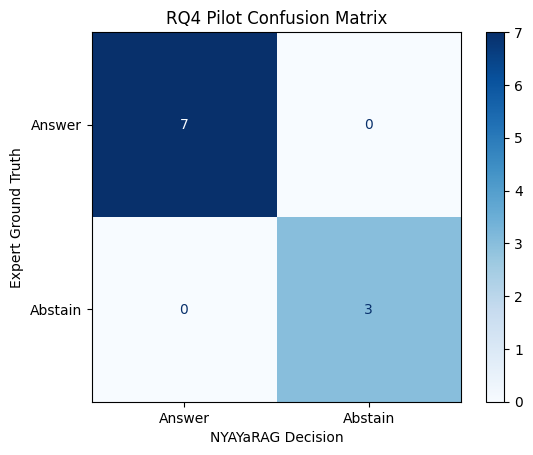


Confusion-matrix counts
True negatives — correct answers     : 7
False positives — false abstentions  : 0
False negatives — unsafe answers     : 0
True positives — correct abstentions : 3


In [68]:
# ============================================================
# RQ4 PILOT CONFUSION MATRIX
# Positive class = INSUFFICIENT_EVIDENCE / ABSTAIN
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
)

rq4_results = final_decision_check.copy()

# Convert expert and model labels to binary values:
# 0 = ANSWER
# 1 = ABSTAIN / INSUFFICIENT_EVIDENCE

y_true = rq4_results["answerability_label"].map(
    {
        "answerable": 0,
        "insufficient_evidence": 1,
    }
)

y_pred = rq4_results["model_decision"].map(
    {
        "ANSWER": 0,
        "INSUFFICIENT_EVIDENCE": 1,
    }
)

assert y_true.notna().all(), "Unexpected expert answerability label found."
assert y_pred.notna().all(), "Unexpected model decision found."

# Rows = actual class; columns = predicted class
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1],
)

tn, fp, fn, tp = cm.ravel()

print("=" * 76)
print("RQ4 PILOT CONFUSION MATRIX")
print("=" * 76)
print("Positive class: Abstain / Insufficient Evidence")
print()
print(pd.DataFrame(
    cm,
    index=[
        "Actual: Answerable",
        "Actual: Insufficient Evidence",
    ],
    columns=[
        "Predicted: Answer",
        "Predicted: Abstain",
    ],
))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Answer",
        "Abstain",
    ],
)

display.plot(
    values_format="d",
    cmap="Blues",
)

plt.title("RQ4 Pilot Confusion Matrix")
plt.xlabel("NYAYaRAG Decision")
plt.ylabel("Expert Ground Truth")
plt.show()

print("\nConfusion-matrix counts")
print(f"True negatives — correct answers     : {tn}")
print(f"False positives — false abstentions  : {fp}")
print(f"False negatives — unsafe answers     : {fn}")
print(f"True positives — correct abstentions : {tp}")

In [69]:
# ============================================================
# RQ4 PILOT ABSTENTION METRICS
# ============================================================

total = len(y_true)

accuracy = (tp + tn) / total

abstention_precision = precision_score(
    y_true,
    y_pred,
    pos_label=1,
    zero_division=0,
)

abstention_recall = recall_score(
    y_true,
    y_pred,
    pos_label=1,
    zero_division=0,
)

abstention_f1 = f1_score(
    y_true,
    y_pred,
    pos_label=1,
    zero_division=0,
)

correct_abstention_rate = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else 0
)

false_answer_rate = (
    fn / (tp + fn)
    if (tp + fn) > 0
    else 0
)

false_abstention_rate = (
    fp / (fp + tn)
    if (fp + tn) > 0
    else 0
)

print("=" * 76)
print("RQ4 PILOT ABSTENTION METRICS")
print("=" * 76)
print(f"Questions evaluated          : {total}")
print(f"Overall decision accuracy    : {accuracy:.3f}")
print(f"Correct-abstention rate      : {correct_abstention_rate:.3f}")
print(f"Abstention precision         : {abstention_precision:.3f}")
print(f"Abstention recall            : {abstention_recall:.3f}")
print(f"Abstention F1-score          : {abstention_f1:.3f}")
print(f"False-answer rate            : {false_answer_rate:.3f}")
print(f"False-abstention rate        : {false_abstention_rate:.3f}")

RQ4 PILOT ABSTENTION METRICS
Questions evaluated          : 10
Overall decision accuracy    : 1.000
Correct-abstention rate      : 1.000
Abstention precision         : 1.000
Abstention recall            : 1.000
Abstention F1-score          : 1.000
False-answer rate            : 0.000
False-abstention rate        : 0.000
